# Sensitivity of trends to current definitions
work on one current at a time

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cartopy import crs, feature
import cmocean as cm
import matplotlib.lines as mlines
import statsmodels.api as sm
from shapely.ops import unary_union
import geopandas as gpd
from shapely.geometry import Point, box

import warnings
warnings.filterwarnings("ignore")

IOPATH = '/ocean/rbeutel/MOAD/analysis-becca/Synthesis/data/CCS_obs.csv'

In [2]:
obs = pd.read_csv(IOPATH)

# reduce potential bias caused by sampling programs going out in different months
# summer only (april-sep inclusive) based on PreliminaryCurrentAnalysis.ipynb
obs = obs[(obs.month>=4)&(obs.month<=9)]
obs

,Unnamed: 0.1,Unnamed: 0,time,longitude (degrees_east),latitude (degrees_north),depth (m),pressure (dbar),temperature (degC),salinity (g kg-1),density (kg m-3),...,TA (uM),DIC (uM),source,current,location,[TA-DIC] (uM),year,month,NSdist,EWdist
0,0,0,1933-07-25 00:00:00+00:00,-126.76,49.34,1.0,1.008587,NaN,32.070847,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
1,1,1,1933-07-25 00:00:00+00:00,-126.76,49.34,2.0,2.017180,NaN,32.090943,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
2,2,2,1933-07-25 00:00:00+00:00,-126.76,49.34,4.0,4.034378,NaN,32.090906,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
3,3,3,1933-07-25 00:00:00+00:00,-126.76,49.34,6.0,6.051598,NaN,32.090870,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
4,4,4,1933-07-25 00:00:00+00:00,-126.76,49.34,10.0,10.086095,NaN,32.181305,NaN,...,NaN,NaN,ios bottle,shelf,shelf,NaN,1933,7,-158.177943,-0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1725140,1725140,1809685,2024-09-30 00:00:00+00:00,-124.57,46.99,0.0,0.000000,10.000050,33.328536,1025.527358,...,NaN,NaN,ooi,shelf,shelf,NaN,2024,9,133.256480,-0.0
1725141,1725141,1809686,2024-09-30 00:00:00+00:00,-124.56,46.99,0.0,0.000000,12.388119,32.661681,1024.585241,...,NaN,NaN,ooi,shelf,shelf,NaN,2024,9,133.256480,-0.0
1725142,1725142,1809687,2024-09-30 00:00:00+00:00,-124.31,44.64,0.0,0.000000,9.441516,33.522238,1025.769626,...,NaN,NaN,ooi,shelf,shelf,NaN,2024,9,377.942065,NaN
1725143,1725143,1809688,2024-09-30 00:00:00+00:00,-124.27,47.13,0.0,0.000000,11.669242,32.555657,1024.637082,...,NaN,NaN,ooi,shelf,shelf,NaN,2024,9,133.256480,-0.0


In [3]:
obs.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', 'time', 'longitude (degrees_east)',
       'latitude (degrees_north)', 'depth (m)', 'pressure (dbar)',
       'temperature (degC)', 'salinity (g kg-1)', 'density (kg m-3)', 'spice',
       'sigma0 (kg m-3)', 'DO (umol kg-1)', 'NO3 (uM)', 'TA (uM)', 'DIC (uM)',
       'source', 'current', 'location', '[TA-DIC] (uM)', 'year', 'month',
       'NSdist', 'EWdist'],
      dtype='str')

In [4]:
dmin, dmax = -1415, 2950
edges   = np.linspace(dmin, dmax, 10)
edges

array([-1415.,  -930.,  -445.,    40.,   525.,  1010.,  1495.,  1980.,
        2465.,  2950.])

In [5]:
def annual_bin_means(
    obs_used, var_string, edges, *,
    do_interp=True, min_obs_per_year=3,
    depth_step=10.0, depth_bin=1.0,
    min_coverage=0.9, max_vertical_gap=50.0,
    min_depth_range=30.0, depth_range=None
):
    """Return annual bin means, valid raw observations, and selected depth interval.

    With do_interp=True and depth_range=None, the selection and averaging
    reproduce the mathematical method of the reference plot_ratediff_NS_CI:
      - include the final horizontal-bin right edge (clip to last bin)
      - bin depths, then construct one mean profile per bin and year
      - use coverage from ALL eligible profiles to select the depth range
      - choose the longest contiguous interval meeting min_coverage AND
        min_depth_range (tie-break by mean coverage)
      - exclude profiles that do not span that interval or have gaps > the
        threshold INTERSECTING the interval
      - linearly interpolate without extrapolation; integrate by trapezoid
        and divide by the selected depth interval's width

    do_interp=False preserves the non-interpolated annual-mean option.
    depth_range=(z0, z1) explicitly overrides the automatic range selection.
    """
    edges = np.asarray(edges, dtype=float)
    if edges.ndim != 1 or len(edges) < 2 or not np.all(np.diff(edges) > 0):
        raise ValueError("edges must be strictly increasing.")
    if not 0 < min_coverage <= 1:
        raise ValueError("min_coverage must lie in (0, 1].")
    if depth_step <= 0 or depth_bin <= 0 or min_depth_range <= 0:
        raise ValueError("Depth spacings and min_depth_range must be positive.")
    if max_vertical_gap is not None and max_vertical_gap <= 0:
        raise ValueError("max_vertical_gap must be positive or None.")
    if min_obs_per_year < 1:
        raise ValueError("min_obs_per_year must be at least 1.")

    dist = np.asarray(obs_used['dist'], dtype=float)
    year = np.asarray(obs_used['year'], dtype=float)
    value = np.asarray(obs_used[var_string], dtype=float)
    if not (len(dist) == len(year) == len(value)):
        raise ValueError("dist, year, and property must have equal lengths.")

    # The reference excludes non-finite depths, includes the endpoint,
    # and assigns that endpoint to the final horizontal bin.
    valid = (
        np.isfinite(dist) & np.isfinite(year) & np.isfinite(value) &
        (dist >= edges[0]) & (dist <= edges[-1])
    )
    if do_interp:
        depth = np.asarray(obs_used['depth (m)'], dtype=float)
        if len(depth) != len(dist):
            raise ValueError("depth and distance must have equal lengths.")
        valid &= np.isfinite(depth)

    bin_id = np.searchsorted(edges, dist[valid], side='right') - 1
    bin_id = np.clip(bin_id, 0, len(edges) - 2)
    raw = pd.DataFrame({
        'bin': bin_id, 'year': year[valid], 'val': value[valid]
    })
    columns = ['bin', 'year', 'mean', 'n', 'n_depth']
    empty = pd.DataFrame(columns=columns)
    if raw.empty:
        return empty, raw, (np.nan, np.nan)

    if not do_interp:
        annual = (raw.groupby(['bin', 'year'], as_index=False)['val']
                  .agg(mean='mean', n='size'))
        annual = annual.loc[annual['n'] >= min_obs_per_year].copy()
        annual['n_depth'] = np.nan
        return annual[columns], raw, (np.nan, np.nan)

    # 1. Build annual profiles, WITHOUT pre-rejecting vertical gaps.
    raw['depth'] = depth[valid]
    raw['z_bin'] = np.round(raw['depth'] / depth_bin) * depth_bin
    profiles = {}
    cover = []
    for (i, yr), group in raw.groupby(['bin', 'year']):
        n = len(group)
        if n < min_obs_per_year:
            continue
        p = group.groupby('z_bin')['val'].mean().sort_index()
        if len(p) < 2:
            continue
        z = p.index.to_numpy(dtype=float)
        v = p.to_numpy(dtype=float)
        profiles[(i, yr)] = (z, v, n)
        cover.append((z[0], z[-1]))

    if not profiles:
        return empty, raw, (np.nan, np.nan)

    # 2. Select depth interval using ALL eligible annual profiles.
    if depth_range is None:
        cover = np.asarray(cover, dtype=float)
        z_grid = np.arange(
            np.ceil(cover[:, 0].min() / depth_step) * depth_step,
            np.floor(cover[:, 1].max() / depth_step) * depth_step
            + depth_step * 0.5,
            depth_step
        )
        if len(z_grid) < 2:
            return empty, raw, (np.nan, np.nan)

        coverage = (
            (z_grid[:, None] >= cover[None, :, 0]) &
            (z_grid[:, None] <= cover[None, :, 1])
        ).mean(axis=1)
        sufficient = coverage >= min_coverage
        changes = np.diff(np.r_[False, sufficient, False].astype(int))
        starts = np.where(changes == 1)[0]
        ends = np.where(changes == -1)[0] - 1
        candidates = [
            (z_grid[e] - z_grid[s], coverage[s:e + 1].mean(), s, e)
            for s, e in zip(starts, ends)
            if z_grid[e] - z_grid[s] >= min_depth_range
        ]
        if not candidates:
            return empty, raw, (np.nan, np.nan)
        _, _, s, e = max(candidates)
        z_common = z_grid[s:e + 1]
    else:
        z0, z1 = map(float, depth_range)
        if not (np.isfinite(z0) and np.isfinite(z1)) or z1 - z0 < min_depth_range:
            raise ValueError("depth_range must be finite and at least min_depth_range wide.")
        z_common = np.r_[np.arange(z0, z1, depth_step), z1]

    zmin, zmax = float(z_common[0]), float(z_common[-1])

    # 3. Exclude profiles with insufficient coverage or oversized gaps
    # intersecting the selected interval; use a trapezoidal layer mean.
    rows = []
    for (i, yr), (z, v, n) in profiles.items():
        if z[0] > zmin or z[-1] < zmax:
            continue
        if max_vertical_gap is not None:
            gaps = np.diff(z)
            intersects = (z[:-1] < zmax) & (z[1:] > zmin)
            if np.any(gaps[intersects] > max_vertical_gap):
                continue
        vi = np.interp(z_common, z, v)
        mean = np.trapezoid(vi, z_common) / (zmax - zmin)
        if np.isfinite(mean):
            rows.append((i, yr, mean, n, len(z)))

    annual = pd.DataFrame(rows, columns=columns)
    return annual, raw, (zmin, zmax)


def _fit_annual_trend(group, *, min_years=4, min_span_years=10, hac_maxlags=1):
    """Return (OLS fit, slope CI, span) or None when no valid trend exists."""
    if len(group) < max(min_years, 3):
        return None
    g = group.sort_values('year')
    x = g['year'].to_numpy(dtype=float)
    y = g['mean'].to_numpy(dtype=float)
    span = float(x.max() - x.min() + 1)
    if span < min_span_years or not (np.isfinite(x).all() and np.isfinite(y).all()):
        return None
    X = sm.add_constant(x, has_constant='add')
    if np.linalg.matrix_rank(X) < 2:
        return None
    try:
        fit = sm.OLS(y, X).fit(cov_type='HAC', cov_kwds={'maxlags': int(hac_maxlags)})
        ci = np.asarray(fit.conf_int(alpha=0.05))
    except (ValueError, IndexError, np.linalg.LinAlgError):
        return None
    if (ci.shape != (2, 2) or not np.isfinite(ci).all() or
        not np.isfinite(fit.params).all() or
        not (ci[1, 0] <= fit.params[1] <= ci[1, 1])):
        return None
    return fit, ci, span


def plot_ratediff_NS_CI(
    obs_used, var_string, ax, colour, *,
    n_bins=9, hac_maxlags=1, min_obs_per_year=3,
    min_years=4, min_span_years=10, offset=0,
    do_interp=True, depth_step=10.0, depth_bin=1.0,
    min_coverage=0.9, max_vertical_gap=50.0,
    min_depth_range=30.0, depth_range=None
):
    ylim_dict = {
        'spice': [-0.03, 0.02], 'temperature (degC)': [-0.12, 0.12],
        'salinity (g kg-1)': [-0.02, 0.02], 'DO (umol kg-1)': [-4, 4],
        'NO3 (uM)': [-1.5, 0.5], '[TA-DIC] (uM)': [-10, 14]
    }
    dmin, dmax = -1415, 2950
    edges = np.linspace(dmin, dmax, n_bins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:]) + offset

    annual, raw, selected_depth = annual_bin_means(
        obs_used, var_string, edges,
        do_interp=do_interp, min_obs_per_year=min_obs_per_year,
        depth_step=depth_step, depth_bin=depth_bin,
        min_coverage=min_coverage, max_vertical_gap=max_vertical_gap,
        min_depth_range=min_depth_range, depth_range=depth_range
    )
    slopes = np.full(n_bins, np.nan)
    lo95 = np.full(n_bins, np.nan)
    hi95 = np.full(n_bins, np.nan)
    count = np.full(n_bins, np.nan)
    year_span = np.full(n_bins, np.nan)

    for i in range(n_bins):
        n_raw = int((raw['bin'] == i).sum())
        if n_raw:
            count[i] = n_raw  # Original raw-observation count.
        g = annual.loc[annual['bin'] == i]
        result = _fit_annual_trend(
            g, min_years=min_years,
            min_span_years=min_span_years, hac_maxlags=hac_maxlags
        )
        if result is None:
            continue
        fit, ci, span = result
        slopes[i] = fit.params[1]
        lo95[i], hi95[i] = ci[1]
        year_span[i] = span

    def _plot_group(mask, alpha):
        if not np.any(mask):
            return
        yerr = np.vstack((slopes[mask] - lo95[mask],
                          hi95[mask] - slopes[mask]))
        ax.errorbar(centers[mask], slopes[mask], yerr=yerr,
                    fmt='.', ms=7, c=colour, alpha=alpha,
                    label='95% CI', zorder=4)

    valid = (np.isfinite(slopes) & np.isfinite(lo95) &
             np.isfinite(hi95) & np.isfinite(year_span))
    _plot_group(valid & (year_span >= 30), 1.0)
    _plot_group(valid & (year_span < 30), 0.5)

    ax.set_xlim(dmin - 0.05 * (dmax-dmin), dmax + 0.05 * (dmax-dmin))
    ax.set_xticks([-1000, -500, 0, 500, 1000, 1500, 2000, 2500])
    ax.set_xticklabels(['', '-500', '', '500', '', '1500', '', '2500'], rotation=90)
    ax.axhline(0, color='black', lw=1, zorder=3)
    if var_string in ylim_dict:
        ax.set_ylim(ylim_dict[var_string])
        ax.set_yticks([ylim_dict[var_string][0], 0, ylim_dict[var_string][1]])
        ax.set_yticklabels([ylim_dict[var_string][0], 0, ylim_dict[var_string][1]],
                           fontsize=9, rotation=60)
    ax.set_zorder(3)
    ax.patch.set_alpha(0)
    return slopes, hi95-slopes, year_span, count


def plot_panel(ax, slope, err, xloc=0, yloc=0.95):
    text = f"{np.round(slope, 4)} +/- {abs(np.round(err, 4))}"
    edgecolour = "green" if abs(slope) > abs(err) else "red"
    props = dict(boxstyle="round", facecolor="w", edgecolor=edgecolour, alpha=0.7)
    return ax.text(xloc, yloc, text, bbox=props,
                   transform=ax.transAxes, fontsize=9)


def trend_check(
    obs_used, var_string, bin_no, ax, *,
    n_bins=9, min_obs_per_year=3, hac_maxlags=1, iscuc=False,
    min_years=4, min_span_years=10, do_interp=True,
    depth_step=10.0, depth_bin=1.0, min_coverage=0.9,
    max_vertical_gap=50.0, min_depth_range=30.0,
    depth_range=None
):
    if not iscuc:
        ylim_dict = {
            'spice': [-2, 3], 'temperature (degC)': [5, 20],
            'salinity (g kg-1)': [31.7, 35], 'DO (umol kg-1)': [0, 400],
            'NO3 (uM)': [0, 50], '[TA-DIC] (uM)': [-50, 300]
        }
    else:
        ylim_dict = {
            'spice': [-0.4, 1.3], 'temperature (degC)': [5, 12],
            'salinity (g kg-1)': [33, 35], 'DO (umol kg-1)': [0, 200],
            'NO3 (uM)': [20, 40], '[TA-DIC] (uM)': [-30, 100]
        }
    if not 1 <= bin_no <= n_bins:
        raise ValueError("bin_no must be between 1 and n_bins.")

    edges = np.linspace(-1415, 2950, n_bins + 1)
    annual, raw, selected_depth = annual_bin_means(
        obs_used, var_string, edges,
        do_interp=do_interp, min_obs_per_year=min_obs_per_year,
        depth_step=depth_step, depth_bin=depth_bin,
        min_coverage=min_coverage, max_vertical_gap=max_vertical_gap,
        min_depth_range=min_depth_range, depth_range=depth_range
    )
    i = bin_no - 1
    raw_bin = raw.loc[raw['bin'] == i]
    ann_bin = annual.loc[annual['bin'] == i].sort_values('year')
    result = _fit_annual_trend(
        ann_bin, min_years=min_years,
        min_span_years=min_span_years, hac_maxlags=hac_maxlags
    )
    used_years = ann_bin['year'].to_numpy() if result is not None else np.array([])

    # Show observations from excluded years with half the usual opacity.
    is_used = raw_bin['year'].isin(used_years)
    ax.scatter(raw_bin.loc[~is_used, 'year'], raw_bin.loc[~is_used, 'val'],
               s=0.5, color='C0', alpha=0.15)
    ax.scatter(raw_bin.loc[is_used, 'year'], raw_bin.loc[is_used, 'val'],
               s=0.5, color='C0', alpha=0.3)

    # Raw annual means for years excluded from depth standardization or fitting.
    raw_annual = (raw_bin.groupby('year', as_index=False)['val']
                  .mean().rename(columns={'val': 'mean'}))
    ignored = raw_annual.loc[~raw_annual['year'].isin(used_years)]
    ax.scatter(ignored['year'], ignored['mean'], s=12,
               color='tab:olive', alpha=0.5)

    if result is not None:
        fit, ci, span = result
        ax.scatter(ann_bin['year'], ann_bin['mean'], s=12, color='r')
        x_fit = np.array([ann_bin['year'].min(), ann_bin['year'].max()])
        ax.plot(x_fit, fit.predict(sm.add_constant(x_fit, has_constant='add')), 'k')
        err = ci[1, 1] - fit.params[1]
        plot_panel(ax, fit.params[1], err)
    else:
        ax.text(0.5, 0.95, 'No trend', ha='center', va='top',
                transform=ax.transAxes, fontsize=9, color='0.4')

    ax.set_ylim(ylim_dict[var_string])
    ticks = np.linspace(*ylim_dict[var_string], 4)
    ax.set_yticks(ticks)
    ax.set_yticklabels(np.round(ticks, 1))
    plt.tight_layout()

## Shelf
Measurements collected over the shelf excluding brackish water (salinity < 31.5 g/kg)
### Depth

In [6]:
# the main option for the shelf has already been defined
shelf1 = obs[obs['current'] == 'shelf']
shelf1['dist'] = shelf1.NSdist

# what makes sense to play around with here is the importance of the surface layer on shelf properties
# surface cuttoff = range 2 = < 50 m 
# "deep" cuttoff = range 3 = > 50 m

# since these are within the current shelf bounds we can work with the shelf1 dataset
shelf2 = shelf1[(shelf1['depth (m)']<50)]
shelf3 = shelf1[(shelf1['depth (m)']>50)]

Possible issue encountered when converting Shape #95 to GeoJSON: Shapefile format requires that polygons contain at least one exterior ring, but the Shape was entirely made up of interior holes (defined by counter-clockwise orientation in the shapefile format). The rings were still included but were encoded as GeoJSON exterior rings instead of holes.
Possible issue encountered when converting Shape #95 to GeoJSON: Shapefile format requires that polygons contain at least one exterior ring, but the Shape was entirely made up of interior holes (defined by counter-clockwise orientation in the shapefile format). The rings were still included but were encoded as GeoJSON exterior rings instead of holes.
Possible issue encountered when converting Shape #491 to GeoJSON: Shapefile format requires that polygons contain at least one exterior ring, but the Shape was entirely made up of interior holes (defined by counter-clockwise orientation in the shapefile format). The rings were still included b

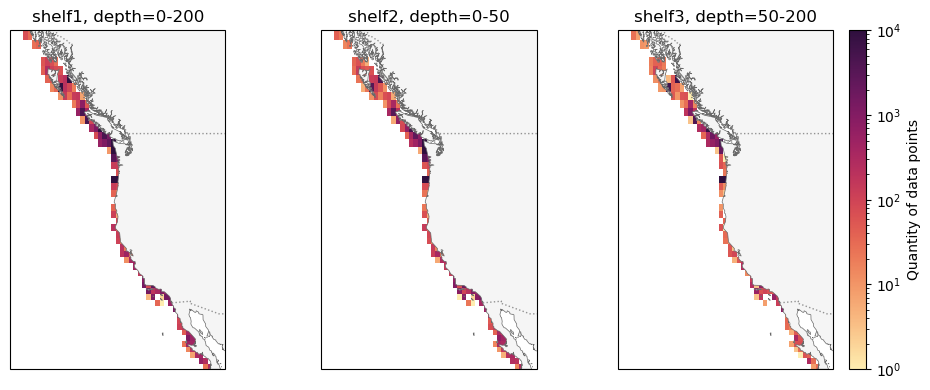

In [7]:
# plot extent

############
# ALL MAPS #
############

xlim, ylim = [-138, -110.2], [25, 57]
proj= crs.Mercator(np.mean(xlim), *ylim)
fig, ax = plt.subplots(1,3,figsize=(10,4),subplot_kw={'projection': proj})

for axs in ax:
    # Make plot area
    axs.set_extent(xlim + ylim)
    # Draw coastline
    axs.add_feature(feature.GSHHSFeature('low', edgecolor='dimgray', facecolor='whitesmoke', lw=0.5), zorder=2)
    # add canada USA border
    axs.add_feature(feature.BORDERS, linestyle='dotted', edgecolor='dimgray', alpha=0.7, zorder=3)

xbin = np.linspace(xlim[0],xlim[1],50)
ybin = np.linspace(ylim[0],ylim[1],50)
vmin,vmax = 1,10000

##########
# shelf1 #
##########
ax[0].set_title("shelf1, depth=0-200")

lon = shelf1['longitude (degrees_east)']
lat = shelf1['latitude (degrees_north)']

# Create 2D histogram
hist1, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Convert bin edges to meshgrid
xcenters = 0.5 * (xedges[:-1] + xedges[1:])
ycenters = 0.5 * (yedges[:-1] + yedges[1:])
X, Y = np.meshgrid(xcenters, ycenters)
# only need to do this once bc bins are the same for all three plots

# Plot using pcolormesh
pcm = ax[0].pcolormesh(X, Y, hist1.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
# fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Quantity of data points")


##########
# shelf2 #
##########
ax[1].set_title("shelf2, depth=0-50")

lon = shelf2['longitude (degrees_east)']
lat = shelf2['latitude (degrees_north)']

# Create 2D histogram
hist2, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Plot using pcolormesh
pcm = ax[1].pcolormesh(X, Y, hist2.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
# fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Quantity of data points")


##########
# shelf3 #
##########
ax[2].set_title("shelf3, depth=50-200")

lon = shelf3['longitude (degrees_east)']
lat = shelf3['latitude (degrees_north)']

# Create 2D histogram
hist3, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Plot using pcolormesh
pcm = ax[2].pcolormesh(X, Y, hist3.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[2], location='right',orientation='vertical',label="Quantity of data points")

plt.tight_layout()

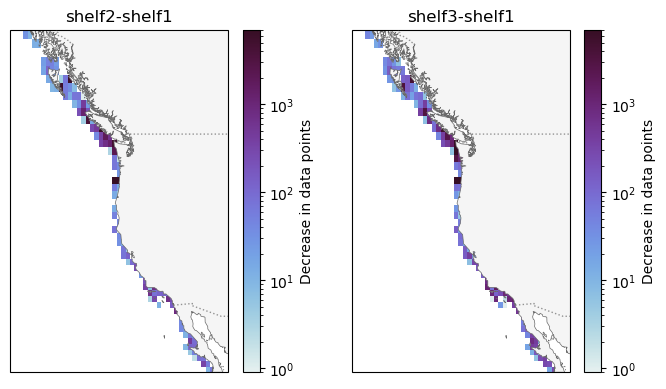

In [8]:
fig, ax = plt.subplots(1,2,figsize=(7,4),subplot_kw={'projection': proj})

for axs in ax:
    # Make plot area
    axs.set_extent(xlim + ylim)
    # Draw coastline
    axs.add_feature(feature.GSHHSFeature('low', edgecolor='dimgray', facecolor='whitesmoke', lw=0.5), zorder=2)
    # add canada USA border
    axs.add_feature(feature.BORDERS, linestyle='dotted', edgecolor='dimgray', alpha=0.7, zorder=3)

vmin,vmax = 7000,1

#################
# shelf2-shelf1 #
#################
ax[0].set_title("shelf2-shelf1")

hist=hist1-hist2

# Plot using pcolormesh
pcm = ax[0].pcolormesh(X, Y, hist.T, cmap=cm.cm.dense, vmin=vmin, vmax=vmax,norm='log', transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Decrease in data points")

#################
# shelf3-shelf1 #
#################
ax[1].set_title("shelf3-shelf1")

hist=hist1-hist3

# Plot using pcolormesh
pcm = ax[1].pcolormesh(X, Y, hist.T, cmap=cm.cm.dense, vmin=vmin, vmax=vmax,norm='log', transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[1], location='right',orientation='vertical',label="Decrease in data points")

plt.tight_layout()

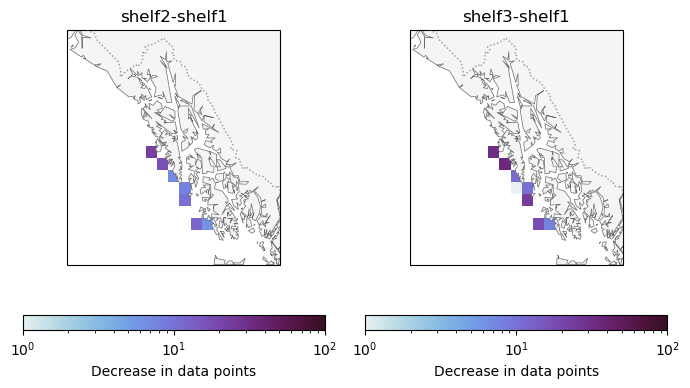

In [9]:
# zoom in on the northernmost bin to get a better idea of why differences are larger there
xlim, ylim = [-140, -130], [54, 60]
# xlim, ylim = [-146, -110.2], [50, 57]
proj= crs.Mercator(np.mean(xlim), *ylim)

xbin = np.linspace(xlim[0],xlim[1],20)
ybin = np.linspace(ylim[0],ylim[1],20)
vmin,vmax = 1,100


########
# shelf1 #
########

lon = shelf1['longitude (degrees_east)'][((shelf1.dist < -930))] # picked according to the bin edges from plot_ratediff_NS_CI()
lat = shelf1['latitude (degrees_north)'][((shelf1.dist < -930))]

# Create 2D histogram
hist1, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Convert bin edges to meshgrid
xcenters = 0.5 * (xedges[:-1] + xedges[1:])
ycenters = 0.5 * (yedges[:-1] + yedges[1:])
X, Y = np.meshgrid(xcenters, ycenters)

########
# shelf2 #
########
lon = shelf2['longitude (degrees_east)'][((shelf2.dist < -930))]
lat = shelf2['latitude (degrees_north)'][((shelf2.dist < -930))]

# Create 2D histogram
hist2, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])


########
# shelf3 #
########
lon = shelf3['longitude (degrees_east)'][((shelf3.dist < -930))]
lat = shelf3['latitude (degrees_north)'][((shelf3.dist < -930))]

# Create 2D histogram
hist3, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# DIFFERENCE
fig, ax = plt.subplots(1,2,figsize=(7,4),subplot_kw={'projection': proj})

for axs in ax:
    # Make plot area
    axs.set_extent(xlim + ylim)
    # Draw coastline
    axs.add_feature(feature.GSHHSFeature('low', edgecolor='dimgray', facecolor='whitesmoke', lw=0.5), zorder=2)
    # add canada USA border
    axs.add_feature(feature.BORDERS, linestyle='dotted', edgecolor='dimgray', alpha=0.7, zorder=3)

#############
# shelf2-shelf1 #
#############
ax[0].set_title("shelf2-shelf1")

hist=hist1-hist2

# Plot using pcolormesh
pcm = ax[0].pcolormesh(X, Y, hist.T, cmap=cm.cm.dense, vmin=vmin, vmax=vmax,norm='log', transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[0], location='bottom',orientation='horizontal',label="Decrease in data points")

#############
# shelf3-shelf1 #
#############
ax[1].set_title("shelf3-shelf1")

hist=hist1-hist3

# Plot using pcolormesh
pcm = ax[1].pcolormesh(X, Y, hist.T, cmap=cm.cm.dense, vmin=vmin, vmax=vmax,norm='log', transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[1], location='bottom',orientation='horizontal',label="Decrease in data points")

plt.tight_layout()

In [10]:
print(len(shelf1[(shelf1.dist < -930)]))
print(len(shelf2[(shelf2.dist < -930)]))
print(len(shelf3[(shelf3.dist < -930)]))
print('\n')


print(np.mean(shelf1.year[(shelf1.dist < -930)]))
print(np.mean(shelf2.year[(shelf2.dist < -930)]))
print(np.mean(shelf3.year[(shelf3.dist < -930)]))
print('\n')


print(np.max(shelf1.year[(shelf1.dist < -930)])-np.min(shelf1.year[(shelf1.dist < -930)]))
print(np.max(shelf2.year[(shelf2.dist < -930)])-np.min(shelf2.year[(shelf2.dist < -930)]))
print(np.max(shelf3.year[(shelf3.dist < -930)])-np.min(shelf3.year[(shelf3.dist < -930)]))
print('\n')

print(np.mean(shelf1['depth (m)'][(shelf1.dist < -930)]))
print(np.mean(shelf2['depth (m)'][(shelf2.dist < -930)]))
print(np.mean(shelf3['depth (m)'][(shelf3.dist < -930)]))


209
126
69


1989.4593301435407
1989.904761904762
1987.8260869565217


64
57
64


52.20574162679426
19.158730158730158
113.0


temperature (degC)
range 1 (violet)
1) span=17.0 years, length=117.0
2) span=40.0 years, length=13802.0
3) span=45.0 years, length=30414.0
4) span=37.0 years, length=143682.0
5) span=72.0 years, length=549.0
6) span=70.0 years, length=2467.0
7) span=72.0 years, length=11179.0
8) span=70.0 years, length=3913.0
9) span=67.0 years, length=4753.0
range 2 (green)
1) span=nan years, length=71.0
2) span=40.0 years, length=6096.0
3) span=45.0 years, length=19790.0
4) span=27.0 years, length=98437.0
5) span=70.0 years, length=357.0
6) span=70.0 years, length=1533.0
7) span=72.0 years, length=7803.0
8) span=71.0 years, length=2516.0
9) span=67.0 years, length=3359.0
range 3 (red)
1) span=nan years, length=37.0
2) span=nan years, length=7660.0
3) span=nan years, length=9925.0
4) span=nan years, length=43843.0
5) span=nan years, length=160.0
6) span=nan years, length=752.0
7) span=nan years, length=2630.0
8) span=nan years, length=1147.0
9) span=nan years, length=961.0


salinity (g kg-1)
range 1 

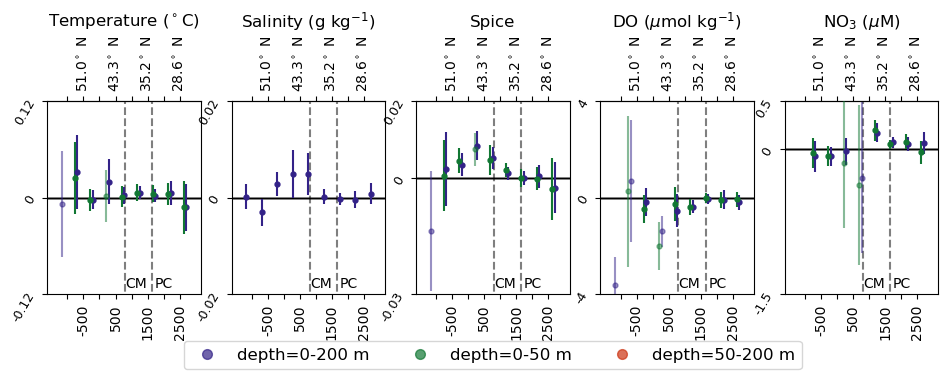

In [11]:
# now looking at how trends change with this new definition
varstrings = ['temperature (degC)','salinity (g kg-1)', 'spice',
       'DO (umol kg-1)', 'NO3 (uM)']
nicestring = ['Temperature ($^\circ$C)','Salinity (g kg$^{-1}$)', 'Spice',
       'DO ($\mu$mol kg$^{-1}$)', 'NO$_3$ ($\mu$M)']

fig,ax = plt.subplots(1,len(varstrings),figsize=[2.3*len(varstrings),2.5])

for i in range(len(varstrings)):
    print(varstrings[i])

    ax[i].set_title(nicestring[i])
    slopes, yerr, span, count = plot_ratediff_NS_CI(shelf1,varstrings[i], ax[i], '#332288')
    print('range 1 (violet)')
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] >= 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('range 2 (green)')
    slopes, yerr, span, count = plot_ratediff_NS_CI(shelf2,varstrings[i], ax[i], '#117733',offset=-80)
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] >= 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")        
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('range 3 (red)')
    slopes, yerr, span, count = plot_ratediff_NS_CI(shelf3,varstrings[i], ax[i], '#CC3311',offset=80)
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] >= 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('\n')

    # make secondary axis
    secax = ax[i].secondary_xaxis('top')
    secax.set_xlim(dmin, dmax)
    secax.set_xticks([-1000,-500,0,500,1000,1500,2000,2500])
    secax.set_xticklabels(['','51.0$^\circ$ N','','43.3$^\circ$ N','','35.2$^\circ$ N','','28.6$^\circ$ N'],rotation=90)

    # add lines for JdF, Cape Mendocino, and Point Conception
    ax[i].plot([805,805],[-1000,1000],'k--',alpha=0.5) # Cape Mendocino
    ax[i].plot([1654,1654],[-1000,1000],'k--',alpha=0.5) # Point Conception
    ax[i].text(0.65,0.02,'CM',ha='right',va='bottom',transform=ax[i].transAxes,fontsize=10)
    ax[i].text(0.82,0.02,'PC',ha='right',va='bottom',transform=ax[i].transAxes,fontsize=10)

# # build legend handles    
legend_handles = []
inlegend = ["depth=0-200 m",'depth=0-50 m','depth=50-200 m']
colours = ['#332288', '#117733', '#CC3311']
markers = ['o','o','o']
for i in range(len(inlegend)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker=markers[i], linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],alpha=0.7,
                          label=inlegend[i]))
# Add a figure-wide legend below the subplots
ax[2].legend(handles=legend_handles, loc='upper center', ncol=3, bbox_to_anchor=(0.5, -0.2), frameon=True,fontsize=12)

# plt.tight_layout()

plt.savefig('/ocean/rbeutel/MOAD/analysis-becca/Synthesis/output/Sensitivity_Shelf_Depth.pdf',bbox_inches='tight')

### Salinity

In [12]:
# the main option for the shelf has already been defined
shelf1 = obs[obs['current'] == 'shelf']
shelf1['dist'] = shelf1.NSdist

# what makes sense to play around with here is the brackish salinity cutoff, going more stringent +0.2 and +0.4 g/kg 
# range 2 -> salinity >= 31.7 
# range 3 -> salinity >= 31.9

# both within the current shelf definition
shelf2 = shelf1[(shelf1['salinity (g kg-1)']>=31.7)]
shelf3 = shelf1[(shelf1['salinity (g kg-1)']>=31.9)]

In [13]:
# curious about depths compared to what we test above

print(f"31.5 -> mean={np.round(np.mean(shelf1['depth (m)']),2)}, min={np.round(np.min(shelf1['depth (m)']),2)}")
print(f"31.7 -> mean={np.round(np.mean(shelf2['depth (m)']),2)}, min={np.round(np.min(shelf2['depth (m)']),2)}")
print(f"31.9 -> mean={np.round(np.mean(shelf3['depth (m)']),2)}, min={np.round(np.min(shelf3['depth (m)']),2)}")

# minor impact on depth, seems to just be removing river outflow and not surface waters at this salinity range

31.5 -> mean=51.19, min=0.0
31.7 -> mean=52.0, min=0.0
31.9 -> mean=53.04, min=0.0


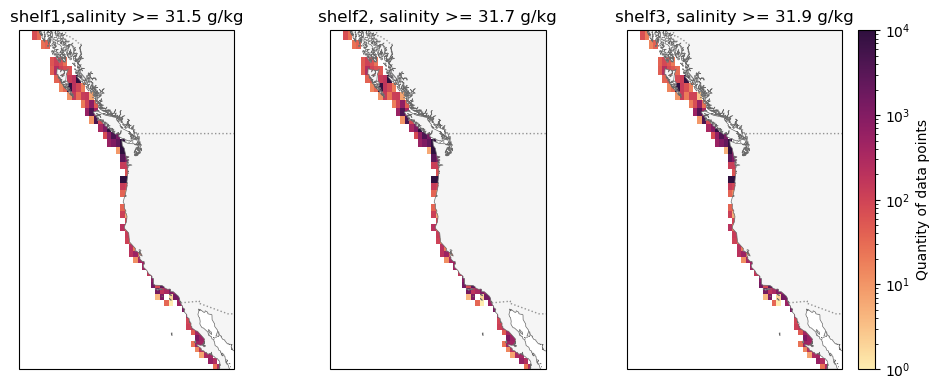

In [14]:
# plot extent

############
# ALL MAPS #
############

xlim, ylim = [-138, -110.2], [25, 57]
proj= crs.Mercator(np.mean(xlim), *ylim)
fig, ax = plt.subplots(1,3,figsize=(10,4),subplot_kw={'projection': proj})

for axs in ax:
    # Make plot area
    axs.set_extent(xlim + ylim)
    # Draw coastline
    axs.add_feature(feature.GSHHSFeature('low', edgecolor='dimgray', facecolor='whitesmoke', lw=0.5), zorder=2)
    # add canada USA border
    axs.add_feature(feature.BORDERS, linestyle='dotted', edgecolor='dimgray', alpha=0.7, zorder=3)

xbin = np.linspace(xlim[0],xlim[1],50)
ybin = np.linspace(ylim[0],ylim[1],50)
vmin,vmax = 1,10000

##########
# shelf1 #
##########
ax[0].set_title("shelf1,salinity >= 31.5 g/kg")

lon = shelf1['longitude (degrees_east)']
lat = shelf1['latitude (degrees_north)']

# Create 2D histogram
hist1, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Convert bin edges to meshgrid
xcenters = 0.5 * (xedges[:-1] + xedges[1:])
ycenters = 0.5 * (yedges[:-1] + yedges[1:])
X, Y = np.meshgrid(xcenters, ycenters)
# only need to do this once bc bins are the same for all three plots

# Plot using pcolormesh
pcm = ax[0].pcolormesh(X, Y, hist1.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
# fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Quantity of data points")


##########
# shelf2 #
##########
ax[1].set_title("shelf2, salinity >= 31.7 g/kg")

lon = shelf2['longitude (degrees_east)']
lat = shelf2['latitude (degrees_north)']

# Create 2D histogram
hist2, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Plot using pcolormesh
pcm = ax[1].pcolormesh(X, Y, hist2.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
# fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Quantity of data points")


##########
# shelf3 #
##########
ax[2].set_title("shelf3, salinity >= 31.9 g/kg")

lon = shelf3['longitude (degrees_east)']
lat = shelf3['latitude (degrees_north)']

# Create 2D histogram
hist3, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Plot using pcolormesh
pcm = ax[2].pcolormesh(X, Y, hist3.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[2], location='right',orientation='vertical',label="Quantity of data points")

plt.tight_layout()

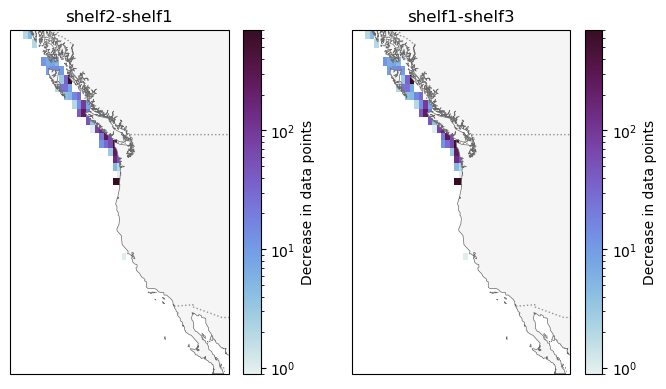

In [15]:
fig, ax = plt.subplots(1,2,figsize=(7,4),subplot_kw={'projection': proj})

for axs in ax:
    # Make plot area
    axs.set_extent(xlim + ylim)
    # Draw coastline
    axs.add_feature(feature.GSHHSFeature('low', edgecolor='dimgray', facecolor='whitesmoke', lw=0.5), zorder=2)
    # add canada USA border
    axs.add_feature(feature.BORDERS, linestyle='dotted', edgecolor='dimgray', alpha=0.7, zorder=3)

vmin,vmax = 700,1

#############
# shelf2-shelf1 #
#############
ax[0].set_title("shelf2-shelf1")

hist=hist1-hist2

# Plot using pcolormesh
pcm = ax[0].pcolormesh(X, Y, hist.T, cmap=cm.cm.dense, vmin=vmin, vmax=vmax,norm='log', transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Decrease in data points")

#############
# shelf3-shelf1 #
#############
ax[1].set_title("shelf1-shelf3")

hist=hist1-hist2
# Plot using pcolormesh
pcm = ax[1].pcolormesh(X, Y, hist.T, cmap=cm.cm.dense, vmin=vmin, vmax=vmax,norm='log', transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[1], location='right',orientation='vertical',label="Decrease in data points")

plt.tight_layout()

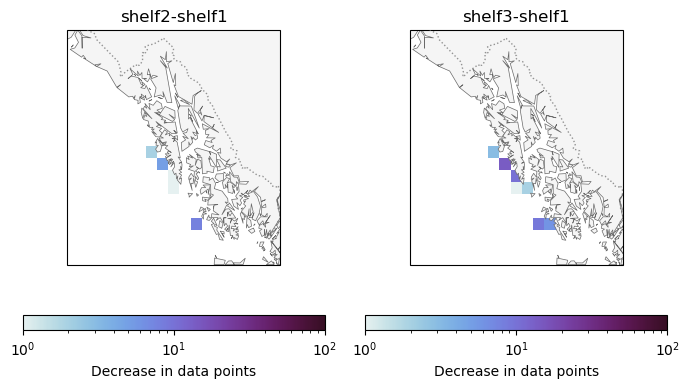

In [16]:
# zoom in on the northernmost bin to get a better idea of why differences are larger there
xlim, ylim = [-140, -130], [54, 60]
# xlim, ylim = [-146, -110.2], [50, 57]
proj= crs.Mercator(np.mean(xlim), *ylim)

xbin = np.linspace(xlim[0],xlim[1],20)
ybin = np.linspace(ylim[0],ylim[1],20)
vmin,vmax = 1,100


########
# shelf1 #
########

lon = shelf1['longitude (degrees_east)'][((shelf1.dist < -930))] # picked according to the bin edges from plot_ratediff_NS_CI()
lat = shelf1['latitude (degrees_north)'][((shelf1.dist < -930))]

# Create 2D histogram
hist1, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Convert bin edges to meshgrid
xcenters = 0.5 * (xedges[:-1] + xedges[1:])
ycenters = 0.5 * (yedges[:-1] + yedges[1:])
X, Y = np.meshgrid(xcenters, ycenters)

########
# shelf2 #
########
lon = shelf2['longitude (degrees_east)'][((shelf2.dist < -930))]
lat = shelf2['latitude (degrees_north)'][((shelf2.dist < -930))]

# Create 2D histogram
hist2, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])


########
# shelf3 #
########
lon = shelf3['longitude (degrees_east)'][((shelf3.dist < -930))]
lat = shelf3['latitude (degrees_north)'][((shelf3.dist < -930))]

# Create 2D histogram
hist3, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# DIFFERENCE
fig, ax = plt.subplots(1,2,figsize=(7,4),subplot_kw={'projection': proj})

for axs in ax:
    # Make plot area
    axs.set_extent(xlim + ylim)
    # Draw coastline
    axs.add_feature(feature.GSHHSFeature('low', edgecolor='dimgray', facecolor='whitesmoke', lw=0.5), zorder=2)
    # add canada USA border
    axs.add_feature(feature.BORDERS, linestyle='dotted', edgecolor='dimgray', alpha=0.7, zorder=3)

#############
# shelf2-shelf1 #
#############
ax[0].set_title("shelf2-shelf1")

hist=hist1-hist2

# Plot using pcolormesh
pcm = ax[0].pcolormesh(X, Y, hist.T, cmap=cm.cm.dense, vmin=vmin, vmax=vmax,norm='log', transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[0], location='bottom',orientation='horizontal',label="Decrease in data points")

#############
# shelf3-shelf1 #
#############
ax[1].set_title("shelf3-shelf1")

hist=hist1-hist3

# Plot using pcolormesh
pcm = ax[1].pcolormesh(X, Y, hist.T, cmap=cm.cm.dense, vmin=vmin, vmax=vmax,norm='log', transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[1], location='bottom',orientation='horizontal',label="Decrease in data points")

plt.tight_layout()

In [17]:
print(len(shelf1[(shelf1.dist < -930)]))
print(len(shelf2[(shelf2.dist < -930)]))
print(len(shelf3[(shelf3.dist < -930)]))
print('\n')


print(np.mean(shelf1.year[(shelf1.dist < -930)]))
print(np.mean(shelf2.year[(shelf2.dist < -930)]))
print(np.mean(shelf3.year[(shelf3.dist < -930)]))
print('\n')


print(np.max(shelf1.year[(shelf1.dist < -930)])-np.min(shelf1.year[(shelf1.dist < -930)]))
print(np.max(shelf2.year[(shelf2.dist < -930)])-np.min(shelf2.year[(shelf2.dist < -930)]))
print(np.max(shelf3.year[(shelf3.dist < -930)])-np.min(shelf3.year[(shelf3.dist < -930)]))
print('\n')

print(np.mean(shelf1['depth (m)'][(shelf1.dist < -930)]))
print(np.mean(shelf2['depth (m)'][(shelf2.dist < -930)]))
print(np.mean(shelf3['depth (m)'][(shelf3.dist < -930)]))

209
192
164


1989.4593301435407
1990.1875
1990.030487804878


64
64
64


52.20574162679426
56.338541666666664
63.48170731707317


temperature (degC)
range 1 (violet)
1) span=17.0 years, length=117.0
2) span=40.0 years, length=13802.0
3) span=45.0 years, length=30414.0
4) span=37.0 years, length=143682.0
5) span=72.0 years, length=549.0
6) span=70.0 years, length=2467.0
7) span=72.0 years, length=11179.0
8) span=70.0 years, length=3913.0
9) span=67.0 years, length=4753.0
range 2 (green)
1) span=17.0 years, length=110.0
2) span=40.0 years, length=12914.0
3) span=45.0 years, length=29461.0
4) span=37.0 years, length=140959.0
5) span=72.0 years, length=549.0
6) span=70.0 years, length=2466.0
7) span=72.0 years, length=11179.0
8) span=70.0 years, length=3913.0
9) span=67.0 years, length=4753.0
range 3 (red)
1) span=nan years, length=93.0
2) 0.0749 +/- 0.0409, span=38.0 years, length=11828.0
3) span=45.0 years, length=28136.0
4) span=37.0 years, length=137688.0
5) span=72.0 years, length=549.0
6) span=70.0 years, length=2465.0
7) span=72.0 years, length=11179.0
8) span=70.0 years, length=3913.0
9) span=67.0 years, leng

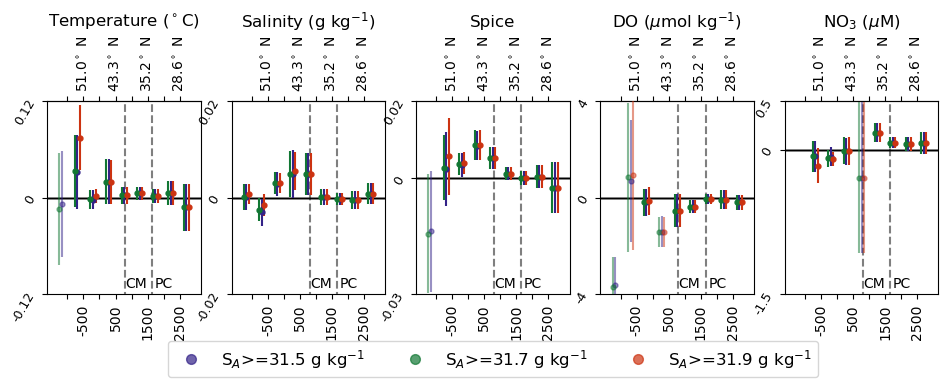

In [18]:
# now looking at how trends change with this new definition
varstrings = ['temperature (degC)','salinity (g kg-1)', 'spice',
       'DO (umol kg-1)', 'NO3 (uM)']

fig,ax = plt.subplots(1,len(varstrings),figsize=[2.3*len(varstrings),2.5])

for i in range(len(varstrings)):
    print(varstrings[i])

    ax[i].set_title(nicestring[i])
    slopes, yerr, span, count = plot_ratediff_NS_CI(shelf1,varstrings[i], ax[i], '#332288')
    print('range 1 (violet)')
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] > 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('range 2 (green)')
    slopes, yerr, span, count = plot_ratediff_NS_CI(shelf2,varstrings[i], ax[i], '#117733',offset=-80)
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] > 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")        
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('range 3 (red)')
    slopes, yerr, span, count = plot_ratediff_NS_CI(shelf3,varstrings[i], ax[i], '#CC3311',offset=80)
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] > 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('\n')

    # make secondary axis
    secax = ax[i].secondary_xaxis('top')
    secax.set_xlim(dmin, dmax)
    secax.set_xticks([-1000,-500,0,500,1000,1500,2000,2500])
    secax.set_xticklabels(['','51.0$^\circ$ N','','43.3$^\circ$ N','','35.2$^\circ$ N','','28.6$^\circ$ N'],rotation=90)

    # add lines for JdF, Cape Mendocino, and Point Conception
    ax[i].plot([805,805],[-1000,1000],'k--',alpha=0.5) # Cape Mendocino
    ax[i].plot([1654,1654],[-1000,1000],'k--',alpha=0.5) # Point Conception
    ax[i].text(0.65,0.02,'CM',ha='right',va='bottom',transform=ax[i].transAxes,fontsize=10)
    ax[i].text(0.82,0.02,'PC',ha='right',va='bottom',transform=ax[i].transAxes,fontsize=10)


# # build legend handles    
legend_handles = []
inlegend = ["S$_A$>=31.5 g kg$^{-1}$",'S$_A$>=31.7 g kg$^{-1}$','S$_A$>=31.9 g kg$^{-1}$']
colours = ['#332288', '#117733', '#CC3311']
markers = ['o','o','o']
for i in range(len(inlegend)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker=markers[i], linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],alpha=0.7,
                          label=inlegend[i]))
# Add a figure-wide legend below the subplots
ax[2].legend(handles=legend_handles, loc='upper center', ncol=3, bbox_to_anchor=(0.5, -0.2), frameon=True,fontsize=12)

# plt.tight_layout()

plt.savefig('/ocean/rbeutel/MOAD/analysis-becca/Synthesis/output/Sensitivity_Shelf_Salinity.pdf',bbox_inches='tight')

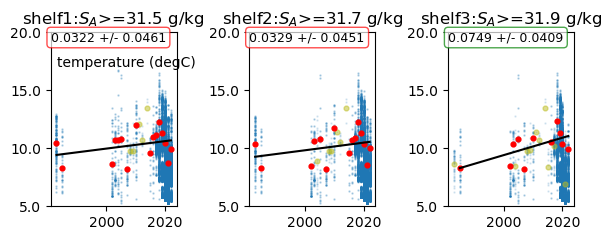

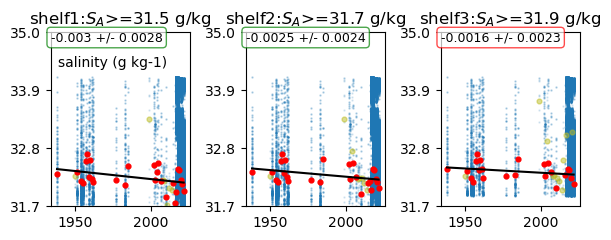

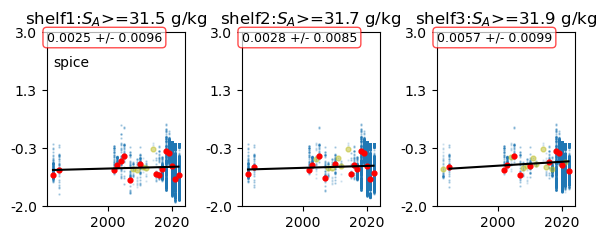

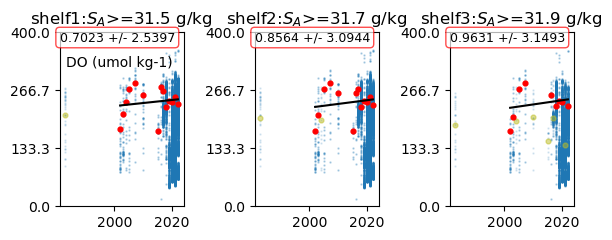

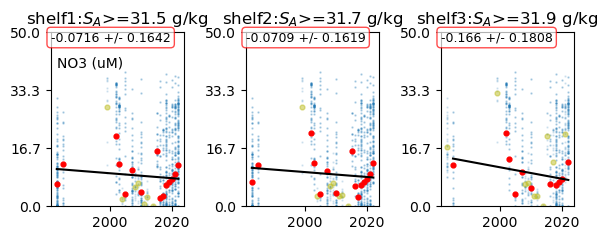

In [19]:
for var in varstrings:
    fig, ax = plt.subplots(1,3,figsize=[6,2.5])

    ax[0].text(0.05,0.8,var,transform=ax[0].transAxes,fontsize=10)

    trend_check(shelf1,var,2,ax[0])
    ax[0].set_title("shelf1:$S_A$>=31.5 g/kg")

    trend_check(shelf2,var,2,ax[1])
    ax[1].set_title("shelf2:$S_A$>=31.7 g/kg")

    trend_check(shelf3,var,2,ax[2])
    ax[2].set_title("shelf3:$S_A$>=31.9 g/kg")

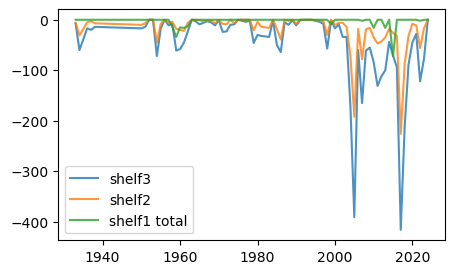

In [20]:
# salinity data loss by year
dmin, dmax =  -1415, 2950
edges   = np.linspace(dmin, dmax, 9+1)

shelf2diff = [len(shelf2['salinity (g kg-1)'][(shelf2['year'] == i) & (shelf2.dist >= edges[2]) & (shelf2.dist <= edges[3])])-len(shelf1['salinity (g kg-1)'][(shelf1['year'] == i) & (shelf1.dist >= edges[2]) & (shelf1.dist <= edges[3])])  for i in set(shelf1.year)] 
shelf3diff = [len(shelf3['salinity (g kg-1)'][(shelf3['year'] == i) & (shelf3.dist >= edges[2]) & (shelf3.dist <= edges[3])])-len(shelf1['salinity (g kg-1)'][(shelf1['year'] == i) & (shelf1.dist >= edges[2]) & (shelf1.dist <= edges[3])])  for i in set(shelf1.year)] 

fig, ax = plt.subplots(1,1,figsize=[5,3])
ax.plot(list(set(shelf1.year)),shelf3diff,alpha=0.8,label="shelf3")
ax.plot(list(set(shelf1.year)),shelf2diff,alpha=0.8,label='shelf2')
ax.plot(list(set(shelf1.year)),[len(shelf1['salinity (g kg-1)'][(shelf1['year'] == i) & (shelf1.dist >= edges[0]) & (shelf1.dist <= edges[1])])*-1  for i in set(shelf1.year)],alpha=0.8,label='shelf1 total')

ax.legend()
# ax.set_ylim([0,-10])

## CC
100-1000 km offshore from 25-50 N, between 45 and 50 N from 100 km offshore to -145.5 E, sigma<= 26.3 kg/m3

In [21]:
# Definition of CC based on Isopycnal and geography

coastline = gpd.read_file('/ocean/ghoeven/MOAD/Data/ne_110m_land.shp')
# Define bounding box for area
bbox = box(-145.5, 20, -110.2, 60)  # lon_min, lat_min, lon_max, lat_max
# Clip the coastline to the bounding box
coastline_clipped = coastline[coastline.intersects(bbox)]
coastline_union = unary_union(coastline_clipped.geometry)

def haversine(lat1, lon1, lat2, lon2):
    """
    Computes great-circle distance between two points on Earth (in km).
    """
    R = 6371.0  # Earth radius in kilometers
    lat1_rad, lon1_rad = np.radians(lat1), np.radians(lon1)
    lat2_rad, lon2_rad = np.radians(lat2), np.radians(lon2)

    dlat = lat2_rad - lat1_rad
    dlon = lon2_rad - lon1_rad

    a = np.sin(dlat / 2)**2 + np.cos(lat1_rad) * np.cos(lat2_rad) * np.sin(dlon / 2)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return R * c

#checks if further than 100km from shore and closer than 1000km
def is_offshore100(lat, lon, coastline_geom, low_threshold_km=100, up_threshold_km=1000):
    point = Point(lon, lat)
    
    # Get nearest point on coastline boundary
    boundary = coastline_geom.boundary
    nearest_point = boundary.interpolate(boundary.project(point))
    
    # Use Haversine instead of geopy
    dist_km = haversine(lat, lon, nearest_point.y, nearest_point.x)
    return (dist_km > low_threshold_km) & (dist_km < up_threshold_km)

def CC_data(obs,*,sigma=26.3,low_threshold_km=100,up_threshold_km=1000,biflat_min=45,biflat_max=50):

    obs_copy = obs.copy()
    obs_copy['is_offshore100'] = obs.apply(
        lambda row: is_offshore100(
            row['latitude (degrees_north)'],
            row['longitude (degrees_east)'],
            coastline_union,
            low_threshold_km=low_threshold_km, 
            up_threshold_km=up_threshold_km
        ),
        axis=1
    )
    base_offshore = obs_copy['is_offshore100']

    # Points between 45–50°N, farther offshore (west) out to -145.5E
    lat = obs['latitude (degrees_north)']
    lon = obs['longitude (degrees_east)']

    extra_offshore = (
        (lat >= biflat_min) &
        (lat <= biflat_max) &
        (lon >= -145.5) &
        (lon < -133) 
    )

    offshore_sel = base_offshore | extra_offshore

    # Selecting data
    mask = (
        (obs['current'] != 'shelf') &
        (lat <= biflat_max) &                 
        (obs['sigma0 (kg m-3)'] <= sigma) & 
        offshore_sel
    )

    return obs[mask]

def cc_dist(NS, EW): # CC dist line function
    abs_a = NS.abs()
    abs_b = EW.abs()

    dist = np.select(
        [
            abs_a < abs_b,       # a closer to zero
            abs_b < abs_a,       # b closer to zero
            abs_a.isna(),        # a NaN, take b
            abs_b.isna()         # b NaN, take a
        ],
        [
            NS,
            EW,
            EW,
            NS
        ],
        default=np.nan
    )

    # and then also default that anywhere that the NS dist is -ve, the EW distance should be taken
    dist[NS<0] = EW[NS<0]
    return dist

### Distance from shore

In [22]:
# the main option for the CC has already been defined
cc1 = obs[obs['current'] == 'CC']
cc1['dist']=cc_dist(cc1.NSdist, cc1.EWdist)

# what makes sense to play around with here is if we started the CC definition further from the shore
# 1st cutoff = range 2 = 75 km 
# 2nd cutoff = range 3 = 150 km

# since these are within the current shelf bounds we can work with the shelf1 dataset
cc2 = CC_data(obs,low_threshold_km=75)
cc2['dist']=cc_dist(cc2.NSdist, cc2.EWdist)

cc3 = CC_data(obs,low_threshold_km=150)
cc3['dist']=cc_dist(cc3.NSdist, cc3.EWdist)

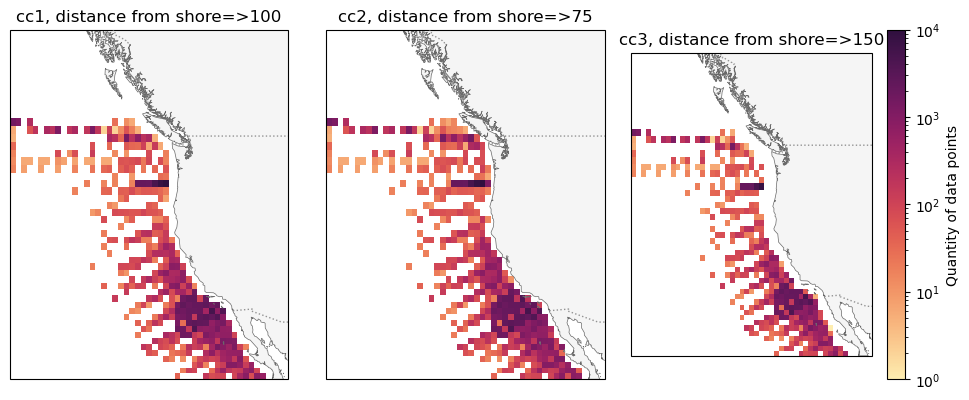

In [23]:
# plot extent

############
# ALL MAPS #
############

xlim, ylim = [-145, -110.2], [25, 57]
proj= crs.Mercator(np.mean(xlim), *ylim)
fig, ax = plt.subplots(1,3,figsize=(10,4),subplot_kw={'projection': proj})

for axs in ax:
    # Make plot area
    axs.set_extent(xlim + ylim)
    # Draw coastline
    axs.add_feature(feature.GSHHSFeature('low', edgecolor='dimgray', facecolor='whitesmoke', lw=0.5), zorder=2)
    # add canada USA border
    axs.add_feature(feature.BORDERS, linestyle='dotted', edgecolor='dimgray', alpha=0.7, zorder=3)

xbin = np.linspace(xlim[0],xlim[1],50)
ybin = np.linspace(ylim[0],ylim[1],50)
vmin,vmax = 1,10000

#######
# cc1 #
#######
ax[0].set_title("cc1, distance from shore=>100")

lon = cc1['longitude (degrees_east)']
lat = cc1['latitude (degrees_north)']

# Create 2D histogram
hist1, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Convert bin edges to meshgrid
xcenters = 0.5 * (xedges[:-1] + xedges[1:])
ycenters = 0.5 * (yedges[:-1] + yedges[1:])
X, Y = np.meshgrid(xcenters, ycenters)
# only need to do this once bc bins are the same for all three plots

# Plot using pcolormesh
pcm = ax[0].pcolormesh(X, Y, hist1.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
# fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Quantity of data points")


#######
# cc2 #
#######
ax[1].set_title("cc2, distance from shore=>75")

lon = cc2['longitude (degrees_east)']
lat = cc2['latitude (degrees_north)']

# Create 2D histogram
hist2, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Plot using pcolormesh
pcm = ax[1].pcolormesh(X, Y, hist2.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
# fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Quantity of data points")


#######
# cc3 #
#######
ax[2].set_title("cc3, distance from shore=>150")

lon = cc3['longitude (degrees_east)']
lat = cc3['latitude (degrees_north)']

# Create 2D histogram
hist3, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Plot using pcolormesh
pcm = ax[2].pcolormesh(X, Y, hist3.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[2], location='right',orientation='vertical',label="Quantity of data points")

plt.tight_layout()

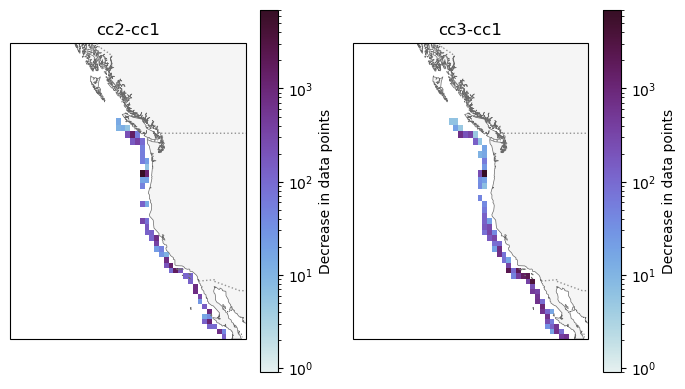

In [24]:
fig, ax = plt.subplots(1,2,figsize=(7,4),subplot_kw={'projection': proj})

for axs in ax:
    # Make plot area
    axs.set_extent(xlim + ylim)
    # Draw coastline
    axs.add_feature(feature.GSHHSFeature('low', edgecolor='dimgray', facecolor='whitesmoke', lw=0.5), zorder=2)
    # add canada USA border
    axs.add_feature(feature.BORDERS, linestyle='dotted', edgecolor='dimgray', alpha=0.7, zorder=3)

vmin,vmax = 7000,1

###########
# cc2-cc1 #
###########
ax[0].set_title("cc2-cc1")

hist=hist2-hist1

# Plot using pcolormesh
pcm = ax[0].pcolormesh(X, Y, hist.T, cmap=cm.cm.dense, vmin=vmin, vmax=vmax,norm='log', transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Decrease in data points")

###########
# cc3-cc1 #
###########
ax[1].set_title("cc3-cc1")

hist=hist1-hist3

# Plot using pcolormesh
pcm = ax[1].pcolormesh(X, Y, hist.T, cmap=cm.cm.dense, vmin=vmin, vmax=vmax,norm='log', transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[1], location='right',orientation='vertical',label="Decrease in data points")

plt.tight_layout()

temperature (degC)
range 1 (violet)
1) 0.0486 +/- 0.0167, span=52.0 years, length=4225.0
2) 0.052 +/- 0.0258, span=52.0 years, length=4131.0
3) span=75.0 years, length=4220.0
4) span=74.0 years, length=33130.0
5) span=73.0 years, length=3333.0
6) span=73.0 years, length=14544.0
7) span=73.0 years, length=92692.0
8) -0.0382 +/- 0.0099, span=72.0 years, length=23643.0
9) span=68.0 years, length=12902.0
range 2 (green)
1) 0.0486 +/- 0.0167, span=52.0 years, length=4225.0
2) 0.052 +/- 0.0258, span=52.0 years, length=4131.0
3) span=75.0 years, length=6744.0
4) span=74.0 years, length=43550.0
5) span=73.0 years, length=3868.0
6) span=73.0 years, length=16304.0
7) span=73.0 years, length=97199.0
8) -0.0347 +/- 0.0101, span=72.0 years, length=25664.0
9) span=68.0 years, length=16116.0
range 3 (red)
1) 0.0508 +/- 0.0179, span=52.0 years, length=4225.0
2) 0.0545 +/- 0.0267, span=52.0 years, length=4131.0
3) span=75.0 years, length=2764.0
4) span=74.0 years, length=19823.0
5) span=59.0 years, len

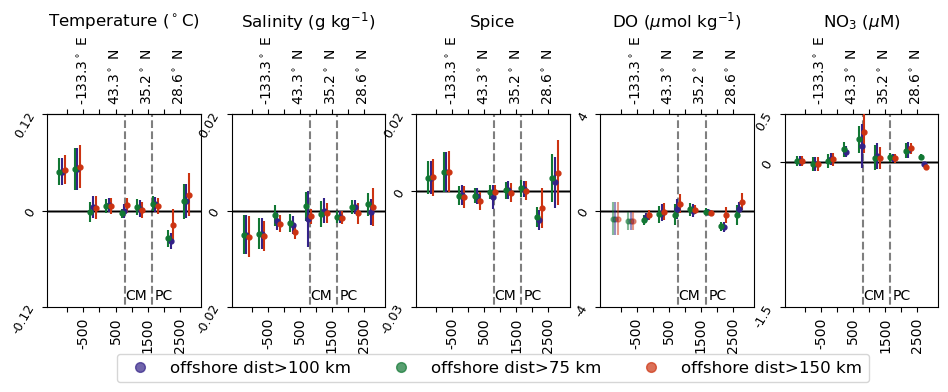

In [25]:
# now looking at how trends change with this new definition
varstrings = ['temperature (degC)','salinity (g kg-1)', 'spice',
       'DO (umol kg-1)', 'NO3 (uM)']

fig,ax = plt.subplots(1,len(varstrings),figsize=[2.3*len(varstrings),2.5])

for i in range(len(varstrings)):
    print(varstrings[i])

    ax[i].set_title(nicestring[i])
    slopes, yerr, span, count = plot_ratediff_NS_CI(cc1,varstrings[i], ax[i], '#332288')
    print('range 1 (violet)')
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] > 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('range 2 (green)')
    slopes, yerr, span, count = plot_ratediff_NS_CI(cc2,varstrings[i], ax[i], '#117733',offset=-80)
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] > 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")        
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('range 3 (red)')
    slopes, yerr, span, count = plot_ratediff_NS_CI(cc3,varstrings[i], ax[i], '#CC3311',offset=80)
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] > 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('\n')

    # make secondary axis
    secax = ax[i].secondary_xaxis('top')
    secax.set_xlim(dmin, dmax)
    secax.set_xticks([-1000,-500,0,500,1000,1500,2000,2500])
    secax.set_xticklabels(['','-133.3$^\circ$ E','','43.3$^\circ$ N','','35.2$^\circ$ N','','28.6$^\circ$ N'],rotation=90)

    # add lines for JdF, Cape Mendocino, and Point Conception
    ax[i].plot([805,805],[-1000,1000],'k--',alpha=0.5) # Cape Mendocino
    ax[i].plot([1654,1654],[-1000,1000],'k--',alpha=0.5) # Point Conception
    ax[i].text(0.65,0.02,'CM',ha='right',va='bottom',transform=ax[i].transAxes,fontsize=10)
    ax[i].text(0.82,0.02,'PC',ha='right',va='bottom',transform=ax[i].transAxes,fontsize=10)


# # build legend handles    
legend_handles = []
inlegend = ["offshore dist>100 km",'offshore dist>75 km','offshore dist>150 km']
colours = ['#332288', '#117733', '#CC3311']
markers = ['o','o','o']
for i in range(len(inlegend)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker=markers[i], linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],alpha=0.7,
                          label=inlegend[i]))
# Add a figure-wide legend below the subplots
ax[2].legend(handles=legend_handles, loc='upper center', ncol=3, bbox_to_anchor=(0.5, -0.2), frameon=True,fontsize=12)

# plt.tight_layout()

plt.savefig('/ocean/rbeutel/MOAD/analysis-becca/Synthesis/output/Sensitivity_CC_inshore.pdf',bbox_inches='tight')

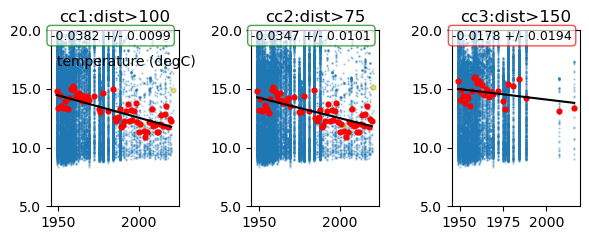

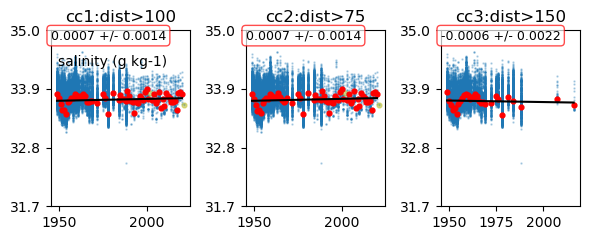

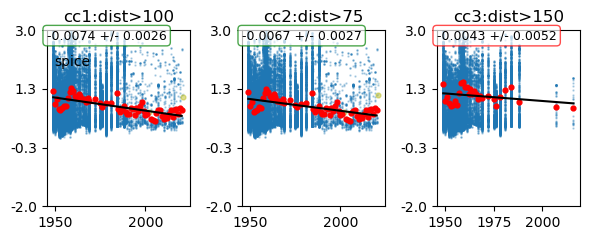

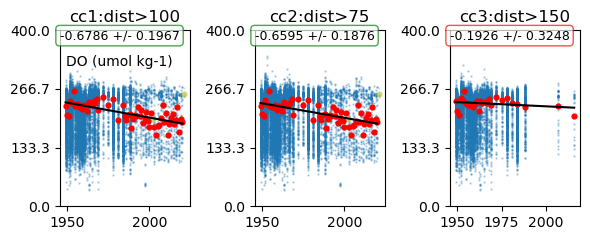

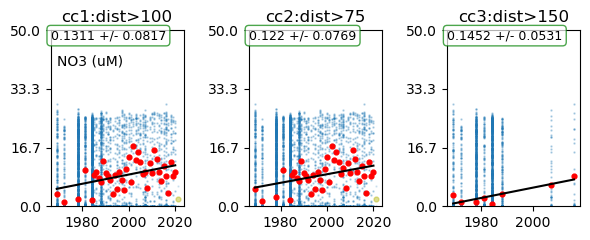

In [26]:
for var in varstrings:
    fig, ax = plt.subplots(1,3,figsize=[6,2.5])

    ax[0].text(0.05,0.8,var,transform=ax[0].transAxes,fontsize=10)

    trend_check(cc1,var,8,ax[0])
    ax[0].set_title("cc1:dist>100")

    trend_check(cc2,var,8,ax[1])
    ax[1].set_title("cc2:dist>75")

    trend_check(cc3,var,8,ax[2])
    ax[2].set_title("cc3:dist>150")

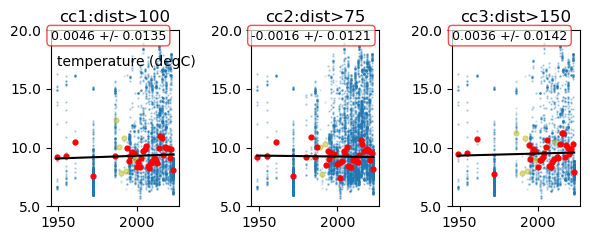

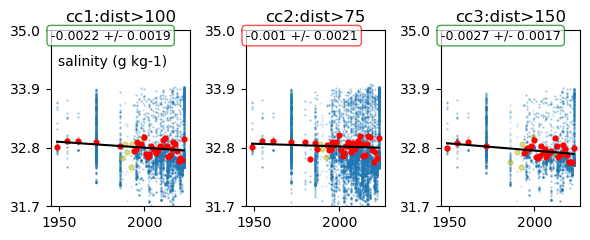

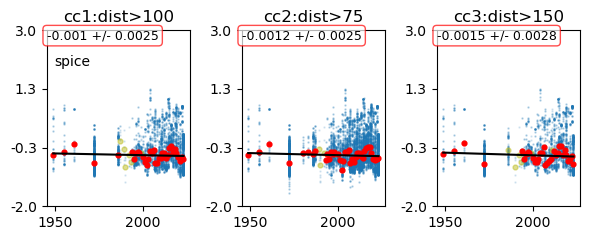

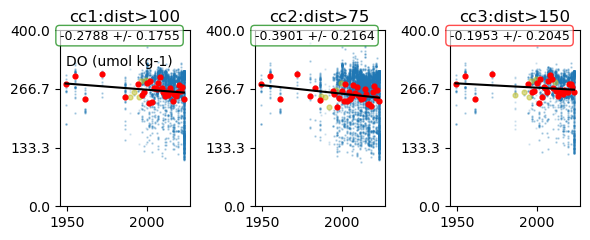

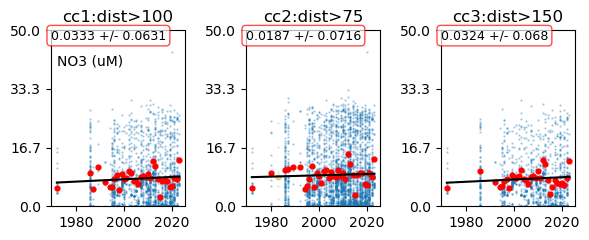

In [27]:
for var in varstrings:
    fig, ax = plt.subplots(1,3,figsize=[6,2.5])

    ax[0].text(0.05,0.8,var,transform=ax[0].transAxes,fontsize=10)

    trend_check(cc1,var,3,ax[0])
    ax[0].set_title("cc1:dist>100")

    trend_check(cc2,var,3,ax[1])
    ax[1].set_title("cc2:dist>75")

    trend_check(cc3,var,3,ax[2])
    ax[2].set_title("cc3:dist>150")

### Distance Offshore

In [28]:
# if we ended the CC definition at different distances offshore 
# original = 1000 km
# 1st cutoff = range 2 = 800 km 
# 2nd cutoff = range 3 = 1200 km

# since these are within the current shelf bounds we can work with the shelf1 dataset
cc2 = CC_data(obs,up_threshold_km=1200)
cc2['dist']=cc_dist(cc2.NSdist, cc2.EWdist)

cc3 = CC_data(obs,up_threshold_km=800)
cc3['dist']=cc_dist(cc3.NSdist, cc3.EWdist)

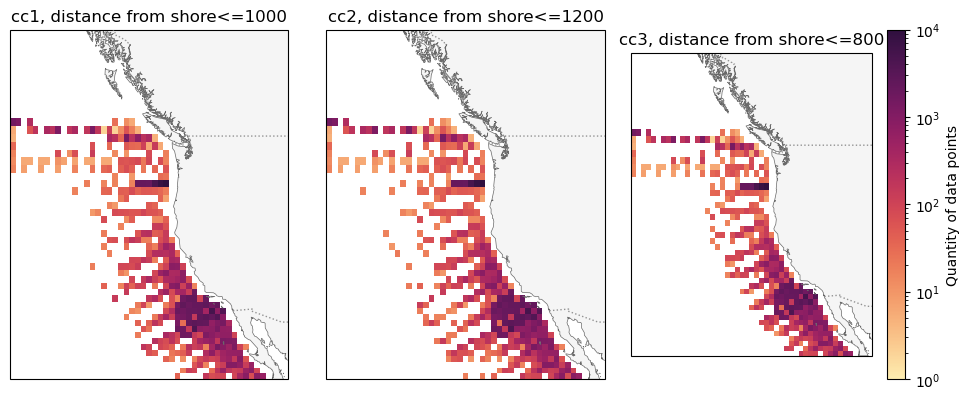

In [29]:
# plot extent

############
# ALL MAPS #
############

xlim, ylim = [-145, -110.2], [25, 57]
proj= crs.Mercator(np.mean(xlim), *ylim)
fig, ax = plt.subplots(1,3,figsize=(10,4),subplot_kw={'projection': proj})

for axs in ax:
    # Make plot area
    axs.set_extent(xlim + ylim)
    # Draw coastline
    axs.add_feature(feature.GSHHSFeature('low', edgecolor='dimgray', facecolor='whitesmoke', lw=0.5), zorder=2)
    # add canada USA border
    axs.add_feature(feature.BORDERS, linestyle='dotted', edgecolor='dimgray', alpha=0.7, zorder=3)

xbin = np.linspace(xlim[0],xlim[1],50)
ybin = np.linspace(ylim[0],ylim[1],50)
vmin,vmax = 1,10000

#######
# cc1 #
#######
ax[0].set_title("cc1, distance from shore<=1000")

lon = cc1['longitude (degrees_east)']
lat = cc1['latitude (degrees_north)']

# Create 2D histogram
hist1, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Convert bin edges to meshgrid
xcenters = 0.5 * (xedges[:-1] + xedges[1:])
ycenters = 0.5 * (yedges[:-1] + yedges[1:])
X, Y = np.meshgrid(xcenters, ycenters)
# only need to do this once bc bins are the same for all three plots

# Plot using pcolormesh
pcm = ax[0].pcolormesh(X, Y, hist1.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
# fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Quantity of data points")


#######
# cc2 #
#######
ax[1].set_title("cc2, distance from shore<=1200")

lon = cc2['longitude (degrees_east)']
lat = cc2['latitude (degrees_north)']

# Create 2D histogram
hist2, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Plot using pcolormesh
pcm = ax[1].pcolormesh(X, Y, hist2.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
# fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Quantity of data points")


#######
# cc3 #
#######
ax[2].set_title("cc3, distance from shore<=800")

lon = cc3['longitude (degrees_east)']
lat = cc3['latitude (degrees_north)']

# Create 2D histogram
hist3, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Plot using pcolormesh
pcm = ax[2].pcolormesh(X, Y, hist3.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[2], location='right',orientation='vertical',label="Quantity of data points")

plt.tight_layout()

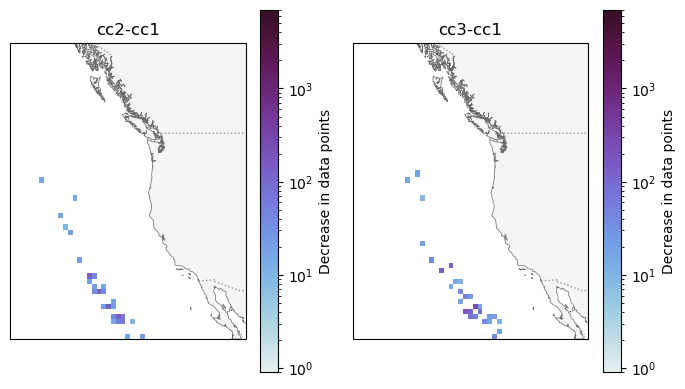

In [30]:
fig, ax = plt.subplots(1,2,figsize=(7,4),subplot_kw={'projection': proj})

for axs in ax:
    # Make plot area
    axs.set_extent(xlim + ylim)
    # Draw coastline
    axs.add_feature(feature.GSHHSFeature('low', edgecolor='dimgray', facecolor='whitesmoke', lw=0.5), zorder=2)
    # add canada USA border
    axs.add_feature(feature.BORDERS, linestyle='dotted', edgecolor='dimgray', alpha=0.7, zorder=3)

vmin,vmax = 7000,1

###########
# cc2-cc1 #
###########
ax[0].set_title("cc2-cc1")

hist=hist2-hist1

# Plot using pcolormesh
pcm = ax[0].pcolormesh(X, Y, hist.T, cmap=cm.cm.dense, vmin=vmin, vmax=vmax,norm='log', transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Decrease in data points")

###########
# cc3-cc1 #
###########
ax[1].set_title("cc3-cc1")

hist=hist1-hist3

# Plot using pcolormesh
pcm = ax[1].pcolormesh(X, Y, hist.T, cmap=cm.cm.dense, vmin=vmin, vmax=vmax,norm='log', transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[1], location='right',orientation='vertical',label="Decrease in data points")

plt.tight_layout()

temperature (degC)
range 1 (violet)
1) 0.0486 +/- 0.0167, span=52.0 years, length=4225.0
2) 0.052 +/- 0.0258, span=52.0 years, length=4131.0
3) span=75.0 years, length=4220.0
4) span=74.0 years, length=33130.0
5) span=73.0 years, length=3333.0
6) span=73.0 years, length=14544.0
7) span=73.0 years, length=92692.0
8) -0.0382 +/- 0.0099, span=72.0 years, length=23643.0
9) span=68.0 years, length=12902.0
range 2 (green)
1) 0.0486 +/- 0.0167, span=52.0 years, length=4225.0
2) 0.052 +/- 0.0258, span=52.0 years, length=4131.0
3) span=75.0 years, length=4220.0
4) span=74.0 years, length=33130.0
5) span=73.0 years, length=3333.0
6) span=73.0 years, length=14544.0
7) span=73.0 years, length=92692.0
8) -0.0382 +/- 0.0099, span=72.0 years, length=23643.0
9) span=68.0 years, length=12902.0
range 3 (red)
1) 0.0486 +/- 0.0167, span=52.0 years, length=4225.0
2) 0.052 +/- 0.0258, span=52.0 years, length=4131.0
3) span=75.0 years, length=4220.0
4) span=74.0 years, length=33130.0
5) span=73.0 years, leng

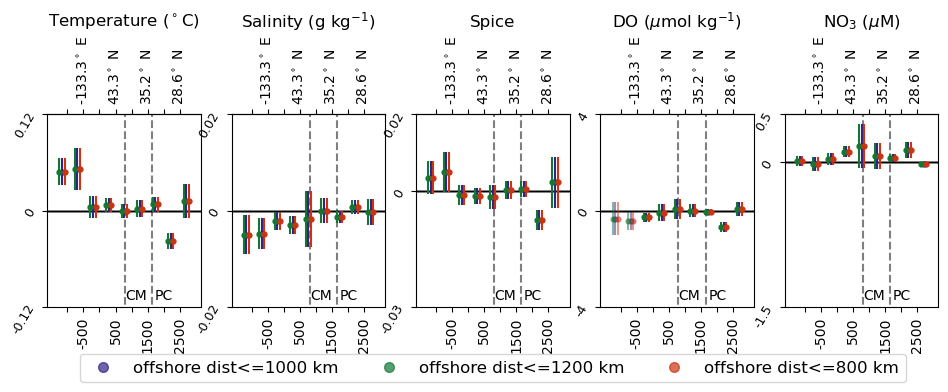

In [31]:
# now looking at how trends change with this new definition
varstrings = ['temperature (degC)','salinity (g kg-1)', 'spice',
       'DO (umol kg-1)', 'NO3 (uM)']

fig,ax = plt.subplots(1,len(varstrings),figsize=[2.3*len(varstrings),2.5])

for i in range(len(varstrings)):
    print(varstrings[i])

    ax[i].set_title(nicestring[i])
    slopes, yerr, span, count = plot_ratediff_NS_CI(cc1,varstrings[i], ax[i], '#332288')
    print('range 1 (violet)')
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] > 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('range 2 (green)')
    slopes, yerr, span, count = plot_ratediff_NS_CI(cc2,varstrings[i], ax[i], '#117733',offset=-80)
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] > 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")        
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('range 3 (red)')
    slopes, yerr, span, count = plot_ratediff_NS_CI(cc3,varstrings[i], ax[i], '#CC3311',offset=80)
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] > 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('\n')

    # make secondary axis
    secax = ax[i].secondary_xaxis('top')
    secax.set_xlim(dmin, dmax)
    secax.set_xticks([-1000,-500,0,500,1000,1500,2000,2500])
    secax.set_xticklabels(['','-133.3$^\circ$ E','','43.3$^\circ$ N','','35.2$^\circ$ N','','28.6$^\circ$ N'],rotation=90)

    # add lines for JdF, Cape Mendocino, and Point Conception
    ax[i].plot([805,805],[-1000,1000],'k--',alpha=0.5) # Cape Mendocino
    ax[i].plot([1654,1654],[-1000,1000],'k--',alpha=0.5) # Point Conception
    ax[i].text(0.65,0.02,'CM',ha='right',va='bottom',transform=ax[i].transAxes,fontsize=10)
    ax[i].text(0.82,0.02,'PC',ha='right',va='bottom',transform=ax[i].transAxes,fontsize=10)


# # build legend handles    
legend_handles = []
inlegend = ["offshore dist<=1000 km",'offshore dist<=1200 km','offshore dist<=800 km']
colours = ['#332288', '#117733', '#CC3311']
markers = ['o','o','o']
for i in range(len(inlegend)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker=markers[i], linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],alpha=0.7,
                          label=inlegend[i]))
# Add a figure-wide legend below the subplots
ax[2].legend(handles=legend_handles, loc='upper center', ncol=3, bbox_to_anchor=(0.5, -0.2), frameon=True,fontsize=12)

# plt.tight_layout()

plt.savefig('/ocean/rbeutel/MOAD/analysis-becca/Synthesis/output/Sensitivity_CC_offshore.pdf',bbox_inches='tight')

### Density

In [32]:
# if set the CC sigma cutoff differently
# original = 26.3 
# range 2 = 26.2
# range 3 = 26.4

# since these are within the current shelf bounds we can work with the shelf1 dataset
cc2 = CC_data(obs,sigma=26.2)
cc2['dist']=cc_dist(cc2.NSdist, cc2.EWdist)

cc3 = CC_data(obs,sigma=26.4)
cc3['dist']=cc_dist(cc3.NSdist, cc3.EWdist)

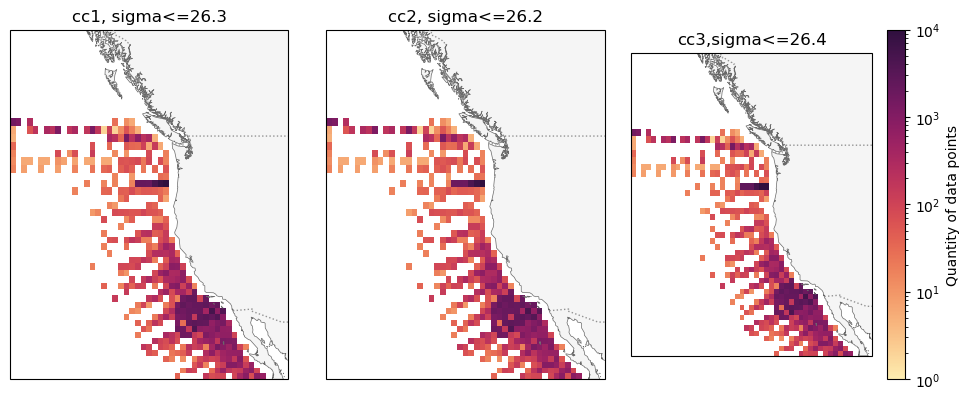

In [33]:
# plot extent

############
# ALL MAPS #
############

xlim, ylim = [-145, -110.2], [25, 57]
proj= crs.Mercator(np.mean(xlim), *ylim)
fig, ax = plt.subplots(1,3,figsize=(10,4),subplot_kw={'projection': proj})

for axs in ax:
    # Make plot area
    axs.set_extent(xlim + ylim)
    # Draw coastline
    axs.add_feature(feature.GSHHSFeature('low', edgecolor='dimgray', facecolor='whitesmoke', lw=0.5), zorder=2)
    # add canada USA border
    axs.add_feature(feature.BORDERS, linestyle='dotted', edgecolor='dimgray', alpha=0.7, zorder=3)

xbin = np.linspace(xlim[0],xlim[1],50)
ybin = np.linspace(ylim[0],ylim[1],50)
vmin,vmax = 1,10000

#######
# cc1 #
#######
ax[0].set_title("cc1, sigma<=26.3")

lon = cc1['longitude (degrees_east)']
lat = cc1['latitude (degrees_north)']

# Create 2D histogram
hist1, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Convert bin edges to meshgrid
xcenters = 0.5 * (xedges[:-1] + xedges[1:])
ycenters = 0.5 * (yedges[:-1] + yedges[1:])
X, Y = np.meshgrid(xcenters, ycenters)
# only need to do this once bc bins are the same for all three plots

# Plot using pcolormesh
pcm = ax[0].pcolormesh(X, Y, hist1.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
# fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Quantity of data points")


#######
# cc2 #
#######
ax[1].set_title("cc2, sigma<=26.2")

lon = cc2['longitude (degrees_east)']
lat = cc2['latitude (degrees_north)']

# Create 2D histogram
hist2, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Plot using pcolormesh
pcm = ax[1].pcolormesh(X, Y, hist2.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
# fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Quantity of data points")


#######
# cc3 #
#######
ax[2].set_title("cc3,sigma<=26.4")

lon = cc3['longitude (degrees_east)']
lat = cc3['latitude (degrees_north)']

# Create 2D histogram
hist3, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Plot using pcolormesh
pcm = ax[2].pcolormesh(X, Y, hist3.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[2], location='right',orientation='vertical',label="Quantity of data points")

plt.tight_layout()

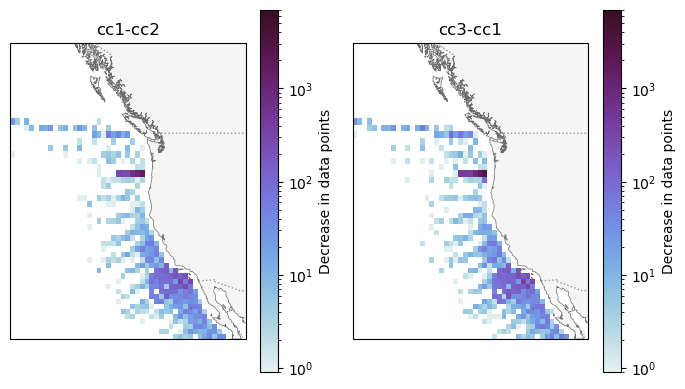

In [34]:
fig, ax = plt.subplots(1,2,figsize=(7,4),subplot_kw={'projection': proj})

for axs in ax:
    # Make plot area
    axs.set_extent(xlim + ylim)
    # Draw coastline
    axs.add_feature(feature.GSHHSFeature('low', edgecolor='dimgray', facecolor='whitesmoke', lw=0.5), zorder=2)
    # add canada USA border
    axs.add_feature(feature.BORDERS, linestyle='dotted', edgecolor='dimgray', alpha=0.7, zorder=3)

vmin,vmax = 7000,1

###########
# cc2-cc1 #
###########
ax[0].set_title("cc1-cc2")

hist=hist1-hist2

# Plot using pcolormesh
pcm = ax[0].pcolormesh(X, Y, hist.T, cmap=cm.cm.dense, vmin=vmin, vmax=vmax,norm='log', transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Decrease in data points")

###########
# cc3-cc1 #
###########
ax[1].set_title("cc3-cc1")

hist=hist3-hist1

# Plot using pcolormesh
pcm = ax[1].pcolormesh(X, Y, hist.T, cmap=cm.cm.dense, vmin=vmin, vmax=vmax,norm='log', transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[1], location='right',orientation='vertical',label="Decrease in data points")

plt.tight_layout()

temperature (degC)
range 1 (violet)
1) 0.0486 +/- 0.0167, span=52.0 years, length=4225.0
2) 0.052 +/- 0.0258, span=52.0 years, length=4131.0
3) span=75.0 years, length=4220.0
4) span=74.0 years, length=33130.0
5) span=73.0 years, length=3333.0
6) span=73.0 years, length=14544.0
7) span=73.0 years, length=92692.0
8) -0.0382 +/- 0.0099, span=72.0 years, length=23643.0
9) span=68.0 years, length=12902.0
range 2 (green)
1) 0.0375 +/- 0.0197, span=52.0 years, length=4137.0
2) 0.0433 +/- 0.0296, span=52.0 years, length=3999.0
3) span=75.0 years, length=3998.0
4) span=74.0 years, length=28866.0
5) 0.0052 +/- 0.0041, span=73.0 years, length=3191.0
6) span=73.0 years, length=13780.0
7) span=73.0 years, length=88063.0
8) -0.0392 +/- 0.0105, span=72.0 years, length=22454.0
9) span=68.0 years, length=12246.0
range 3 (red)
1) 0.0439 +/- 0.0168, span=52.0 years, length=4310.0
2) 0.0467 +/- 0.0257, span=52.0 years, length=4305.0
3) span=75.0 years, length=4541.0
4) span=74.0 years, length=39746.0
5) 

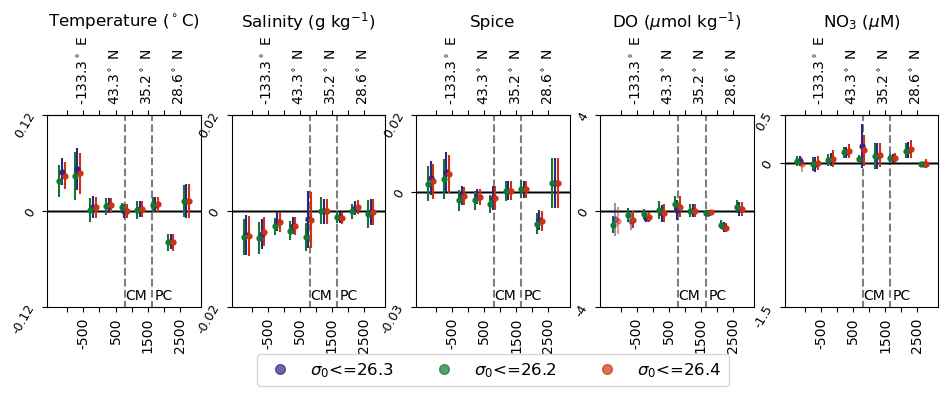

In [35]:
# now looking at how trends change with this new definition
varstrings = ['temperature (degC)','salinity (g kg-1)', 'spice',
       'DO (umol kg-1)', 'NO3 (uM)']

fig,ax = plt.subplots(1,len(varstrings),figsize=[2.3*len(varstrings),2.5])

for i in range(len(varstrings)):
    print(varstrings[i])

    ax[i].set_title(nicestring[i])
    slopes, yerr, span, count = plot_ratediff_NS_CI(cc1,varstrings[i], ax[i], '#332288')
    print('range 1 (violet)')
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] > 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('range 2 (green)')
    slopes, yerr, span, count = plot_ratediff_NS_CI(cc2,varstrings[i], ax[i], '#117733',offset=-80)
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] > 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")        
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('range 3 (red)')
    slopes, yerr, span, count = plot_ratediff_NS_CI(cc3,varstrings[i], ax[i], '#CC3311',offset=80)
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] > 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('\n')

    # make secondary axis
    secax = ax[i].secondary_xaxis('top')
    secax.set_xlim(dmin, dmax)
    secax.set_xticks([-1000,-500,0,500,1000,1500,2000,2500])
    secax.set_xticklabels(['','-133.3$^\circ$ E','','43.3$^\circ$ N','','35.2$^\circ$ N','','28.6$^\circ$ N'],rotation=90)

    # add lines for JdF, Cape Mendocino, and Point Conception
    ax[i].plot([805,805],[-1000,1000],'k--',alpha=0.5) # Cape Mendocino
    ax[i].plot([1654,1654],[-1000,1000],'k--',alpha=0.5) # Point Conception
    ax[i].text(0.65,0.02,'CM',ha='right',va='bottom',transform=ax[i].transAxes,fontsize=10)
    ax[i].text(0.82,0.02,'PC',ha='right',va='bottom',transform=ax[i].transAxes,fontsize=10)

# # build legend handles    
legend_handles = []
inlegend = ["$\sigma _0$<=26.3",'$\sigma _0$<=26.2','$\sigma _0$<=26.4']
colours = ['#332288', '#117733', '#CC3311']
markers = ['o','o','o']
for i in range(len(inlegend)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker=markers[i], linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],alpha=0.7,
                          label=inlegend[i]))
# Add a figure-wide legend below the subplots
ax[2].legend(handles=legend_handles, loc='upper center', ncol=3, bbox_to_anchor=(0.5, -0.2), frameon=True,fontsize=12)

# plt.tight_layout()

plt.savefig('/ocean/rbeutel/MOAD/analysis-becca/Synthesis/output/Sensitivity_CC_density.pdf',bbox_inches='tight')

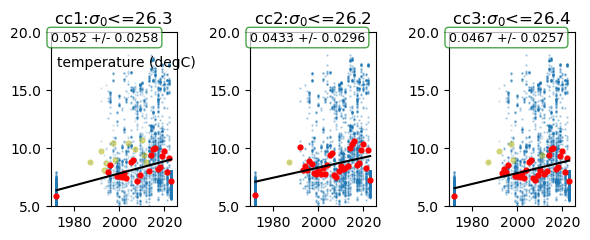

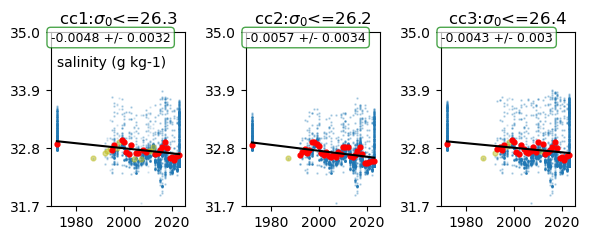

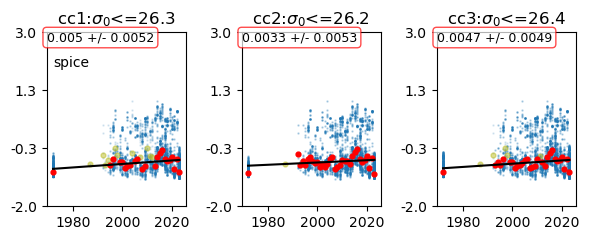

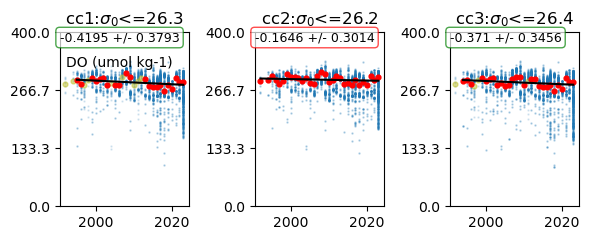

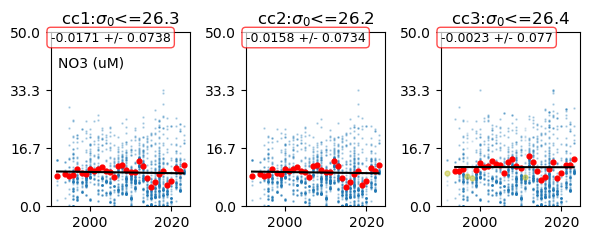

In [36]:
for var in varstrings:
    fig, ax = plt.subplots(1,3,figsize=[6,2.5])

    ax[0].text(0.05,0.8,var,transform=ax[0].transAxes,fontsize=10)

    trend_check(cc1,var,2,ax[0])
    ax[0].set_title("cc1:$\sigma _0$<=26.3")

    trend_check(cc2,var,2,ax[1])
    ax[1].set_title("cc2:$\sigma _0$<=26.2")

    trend_check(cc3,var,2,ax[2])
    ax[2].set_title("cc3:$\sigma _0$<=26.4")

### Bifurcation Band Width

In [37]:
# if set the CC sigma cutoff differently
# original = 45-50 
# thinner, range 2 = 46-49
# thicker, range 3 = 44-51

# since these are within the current shelf bounds we can work with the shelf1 dataset
cc2 = CC_data(obs,biflat_max=49,biflat_min=46)
cc2['dist']=cc_dist(cc2.NSdist, cc2.EWdist)

cc3 = CC_data(obs,biflat_max=51,biflat_min=44)
cc3['dist']=cc_dist(cc3.NSdist, cc3.EWdist)

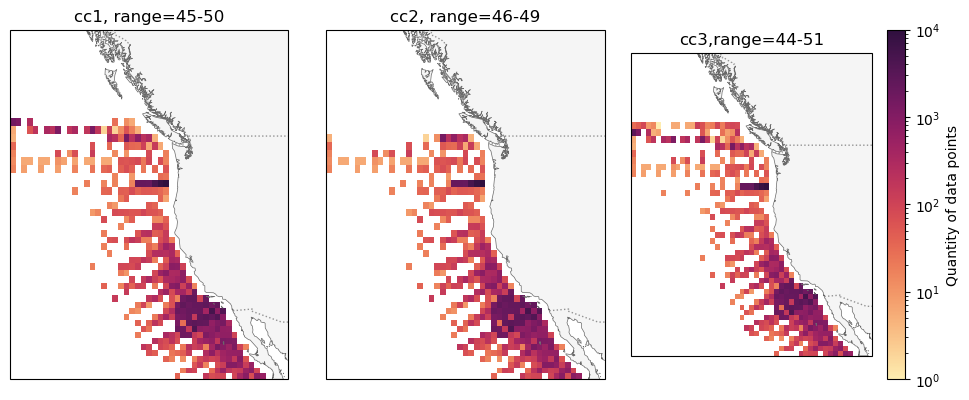

In [38]:
# plot extent

############
# ALL MAPS #
############

xlim, ylim = [-145, -110.2], [25, 57]
proj= crs.Mercator(np.mean(xlim), *ylim)
fig, ax = plt.subplots(1,3,figsize=(10,4),subplot_kw={'projection': proj})

for axs in ax:
    # Make plot area
    axs.set_extent(xlim + ylim)
    # Draw coastline
    axs.add_feature(feature.GSHHSFeature('low', edgecolor='dimgray', facecolor='whitesmoke', lw=0.5), zorder=2)
    # add canada USA border
    axs.add_feature(feature.BORDERS, linestyle='dotted', edgecolor='dimgray', alpha=0.7, zorder=3)

xbin = np.linspace(xlim[0],xlim[1],50)
ybin = np.linspace(ylim[0],ylim[1],50)
vmin,vmax = 1,10000

#######
# cc1 #
#######
ax[0].set_title("cc1, range=45-50")

lon = cc1['longitude (degrees_east)']
lat = cc1['latitude (degrees_north)']

# Create 2D histogram
hist1, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Convert bin edges to meshgrid
xcenters = 0.5 * (xedges[:-1] + xedges[1:])
ycenters = 0.5 * (yedges[:-1] + yedges[1:])
X, Y = np.meshgrid(xcenters, ycenters)
# only need to do this once bc bins are the same for all three plots

# Plot using pcolormesh
pcm = ax[0].pcolormesh(X, Y, hist1.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
# fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Quantity of data points")


#######
# cc2 #
#######
ax[1].set_title("cc2, range=46-49")

lon = cc2['longitude (degrees_east)']
lat = cc2['latitude (degrees_north)']

# Create 2D histogram
hist2, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Plot using pcolormesh
pcm = ax[1].pcolormesh(X, Y, hist2.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
# fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Quantity of data points")


#######
# cc3 #
#######
ax[2].set_title("cc3,range=44-51")

lon = cc3['longitude (degrees_east)']
lat = cc3['latitude (degrees_north)']

# Create 2D histogram
hist3, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Plot using pcolormesh
pcm = ax[2].pcolormesh(X, Y, hist3.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[2], location='right',orientation='vertical',label="Quantity of data points")

plt.tight_layout()

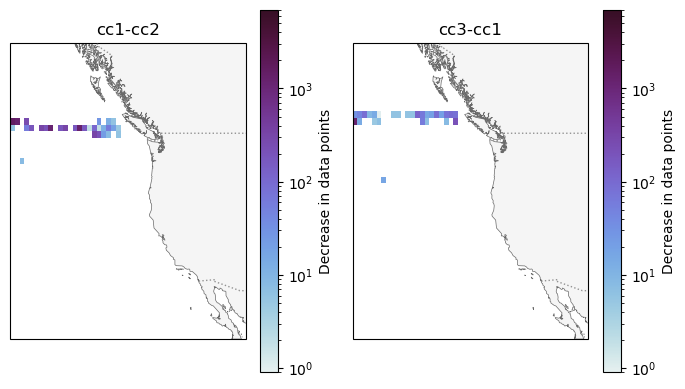

In [39]:
fig, ax = plt.subplots(1,2,figsize=(7,4),subplot_kw={'projection': proj})

for axs in ax:
    # Make plot area
    axs.set_extent(xlim + ylim)
    # Draw coastline
    axs.add_feature(feature.GSHHSFeature('low', edgecolor='dimgray', facecolor='whitesmoke', lw=0.5), zorder=2)
    # add canada USA border
    axs.add_feature(feature.BORDERS, linestyle='dotted', edgecolor='dimgray', alpha=0.7, zorder=3)

vmin,vmax = 7000,1

###########
# cc2-cc1 #
###########
ax[0].set_title("cc1-cc2")

hist=hist1-hist2

# Plot using pcolormesh
pcm = ax[0].pcolormesh(X, Y, hist.T, cmap=cm.cm.dense, vmin=vmin, vmax=vmax,norm='log', transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Decrease in data points")

###########
# cc3-cc1 #
###########
ax[1].set_title("cc3-cc1")

hist=hist3-hist1

# Plot using pcolormesh
pcm = ax[1].pcolormesh(X, Y, hist.T, cmap=cm.cm.dense, vmin=vmin, vmax=vmax,norm='log', transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[1], location='right',orientation='vertical',label="Decrease in data points")

plt.tight_layout()

temperature (degC)
range 1 (violet)
1) 0.0486 +/- 0.0167, span=52.0 years, length=4225.0
2) 0.052 +/- 0.0258, span=52.0 years, length=4131.0
3) span=75.0 years, length=4220.0
4) span=74.0 years, length=33130.0
5) span=73.0 years, length=3333.0
6) span=73.0 years, length=14544.0
7) span=73.0 years, length=92692.0
8) -0.0382 +/- 0.0099, span=72.0 years, length=23643.0
9) span=68.0 years, length=12902.0
range 2 (green)
1) span=nan years, length=105.0
2) span=nan years, length=428.0
3) span=75.0 years, length=3817.0
4) span=74.0 years, length=33130.0
5) span=73.0 years, length=3333.0
6) span=70.0 years, length=14544.0
7) span=73.0 years, length=92692.0
8) -0.035 +/- 0.0088, span=72.0 years, length=23643.0
9) span=68.0 years, length=12902.0
range 3 (red)
1) 0.0496 +/- 0.0173, span=52.0 years, length=5543.0
2) 0.0525 +/- 0.0264, span=52.0 years, length=4199.0
3) span=75.0 years, length=4447.0
4) span=74.0 years, length=33130.0
5) span=73.0 years, length=3333.0
6) span=73.0 years, length=1454

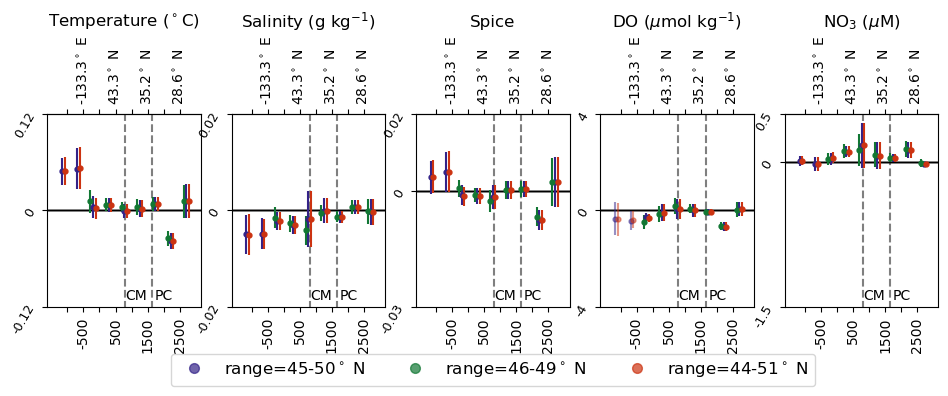

In [40]:
# now looking at how trends change with this new definition
varstrings = ['temperature (degC)','salinity (g kg-1)', 'spice',
       'DO (umol kg-1)', 'NO3 (uM)']

fig,ax = plt.subplots(1,len(varstrings),figsize=[2.3*len(varstrings),2.5])

for i in range(len(varstrings)):
    print(varstrings[i])

    ax[i].set_title(nicestring[i])
    slopes, yerr, span, count = plot_ratediff_NS_CI(cc1,varstrings[i], ax[i], '#332288')
    print('range 1 (violet)')
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] > 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('range 2 (green)')
    slopes, yerr, span, count = plot_ratediff_NS_CI(cc2,varstrings[i], ax[i], '#117733',offset=-80)
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] > 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")        
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('range 3 (red)')
    slopes, yerr, span, count = plot_ratediff_NS_CI(cc3,varstrings[i], ax[i], '#CC3311',offset=80)
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] > 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('\n')

    # make secondary axis
    secax = ax[i].secondary_xaxis('top')
    secax.set_xlim(dmin, dmax)
    secax.set_xticks([-1000,-500,0,500,1000,1500,2000,2500])
    secax.set_xticklabels(['','-133.3$^\circ$ E','','43.3$^\circ$ N','','35.2$^\circ$ N','','28.6$^\circ$ N'],rotation=90)

    # add lines for JdF, Cape Mendocino, and Point Conception
    ax[i].plot([805,805],[-1000,1000],'k--',alpha=0.5) # Cape Mendocino
    ax[i].plot([1654,1654],[-1000,1000],'k--',alpha=0.5) # Point Conception
    ax[i].text(0.65,0.02,'CM',ha='right',va='bottom',transform=ax[i].transAxes,fontsize=10)
    ax[i].text(0.82,0.02,'PC',ha='right',va='bottom',transform=ax[i].transAxes,fontsize=10)


# # build legend handles    
legend_handles = []
inlegend = ["range=45-50$^\circ$ N",'range=46-49$^\circ$ N','range=44-51$^\circ$ N']
colours = ['#332288', '#117733', '#CC3311']
markers = ['o','o','o']
for i in range(len(inlegend)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker=markers[i], linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],alpha=0.7,
                          label=inlegend[i]))
# Add a figure-wide legend below the subplots
ax[2].legend(handles=legend_handles, loc='upper center', ncol=3, bbox_to_anchor=(0.5, -0.2), frameon=True,fontsize=12)

# plt.tight_layout()

plt.savefig('/ocean/rbeutel/MOAD/analysis-becca/Synthesis/output/Sensitivity_CC_BandWidth.pdf',bbox_inches='tight')

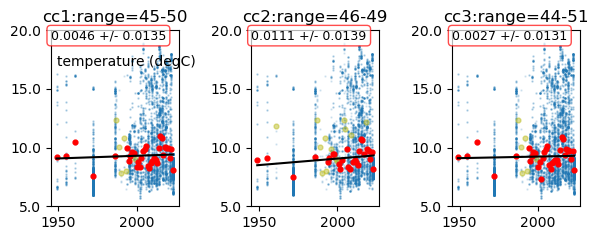

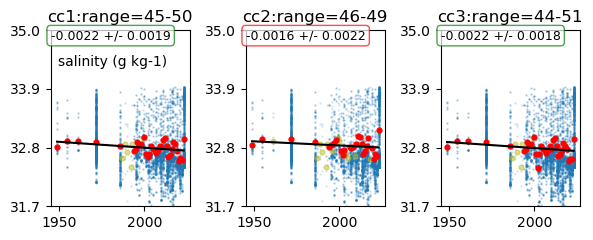

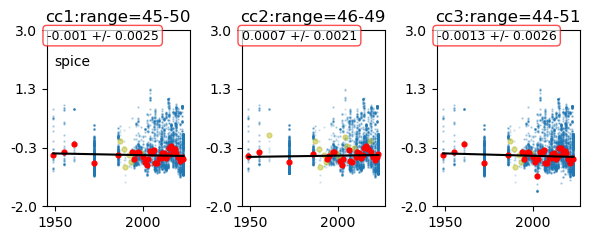

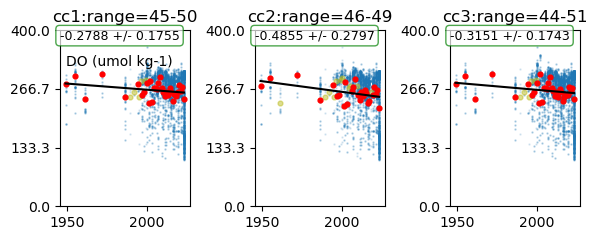

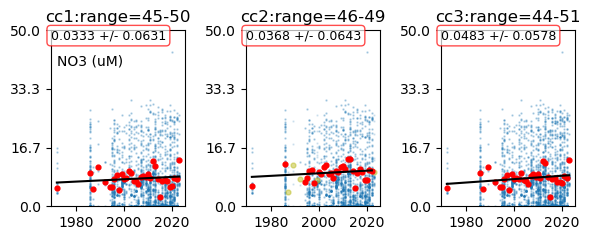

In [41]:
for var in varstrings:
    fig, ax = plt.subplots(1,3,figsize=[6,2.5])

    ax[0].text(0.05,0.8,var,transform=ax[0].transAxes,fontsize=10)

    trend_check(cc1,var,3,ax[0])
    ax[0].set_title("cc1:range=45-50")

    trend_check(cc2,var,3,ax[1])
    ax[1].set_title("cc2:range=46-49")

    trend_check(cc3,var,3,ax[2])
    ax[2].set_title("cc3:range=44-51")

### Bifurcation position

In [42]:
# if set the CC sigma cutoff differently
# original = 45-50 
# north, range 2 = 46-51
# south, range 3 = 44-49

# since these are within the current shelf bounds we can work with the shelf1 dataset
cc2 = CC_data(obs,biflat_max=51,biflat_min=46)
cc2['dist']=cc_dist(cc2.NSdist, cc2.EWdist)

cc3 = CC_data(obs,biflat_max=49,biflat_min=44)
cc3['dist']=cc_dist(cc3.NSdist, cc3.EWdist)

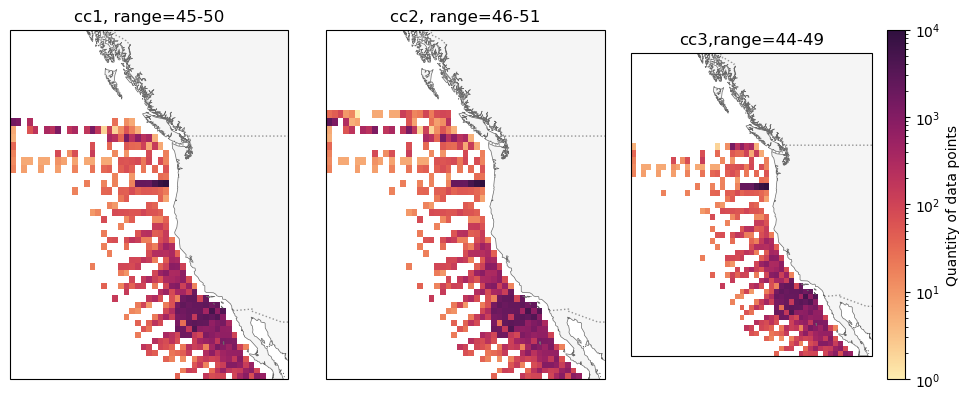

In [43]:
# plot extent

############
# ALL MAPS #
############

xlim, ylim = [-145, -110.2], [25, 57]
proj= crs.Mercator(np.mean(xlim), *ylim)
fig, ax = plt.subplots(1,3,figsize=(10,4),subplot_kw={'projection': proj})

for axs in ax:
    # Make plot area
    axs.set_extent(xlim + ylim)
    # Draw coastline
    axs.add_feature(feature.GSHHSFeature('low', edgecolor='dimgray', facecolor='whitesmoke', lw=0.5), zorder=2)
    # add canada USA border
    axs.add_feature(feature.BORDERS, linestyle='dotted', edgecolor='dimgray', alpha=0.7, zorder=3)

xbin = np.linspace(xlim[0],xlim[1],50)
ybin = np.linspace(ylim[0],ylim[1],50)
vmin,vmax = 1,10000

#######
# cc1 #
#######
ax[0].set_title("cc1, range=45-50")

lon = cc1['longitude (degrees_east)']
lat = cc1['latitude (degrees_north)']

# Create 2D histogram
hist1, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Convert bin edges to meshgrid
xcenters = 0.5 * (xedges[:-1] + xedges[1:])
ycenters = 0.5 * (yedges[:-1] + yedges[1:])
X, Y = np.meshgrid(xcenters, ycenters)
# only need to do this once bc bins are the same for all three plots

# Plot using pcolormesh
pcm = ax[0].pcolormesh(X, Y, hist1.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
# fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Quantity of data points")


#######
# cc2 #
#######
ax[1].set_title("cc2, range=46-51")

lon = cc2['longitude (degrees_east)']
lat = cc2['latitude (degrees_north)']

# Create 2D histogram
hist2, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Plot using pcolormesh
pcm = ax[1].pcolormesh(X, Y, hist2.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
# fig.colorbar(pcm, ax=ax[0], location='right',orientation='vertical',label="Quantity of data points")


#######
# cc3 #
#######
ax[2].set_title("cc3,range=44-49")

lon = cc3['longitude (degrees_east)']
lat = cc3['latitude (degrees_north)']

# Create 2D histogram
hist3, xedges, yedges = np.histogram2d(lon, lat, bins=[xbin,ybin])

# Plot using pcolormesh
pcm = ax[2].pcolormesh(X, Y, hist3.T, cmap=cm.cm.matter, norm='log', vmin=vmin, vmax=vmax, transform=crs.PlateCarree())
fig.colorbar(pcm, ax=ax[2], location='right',orientation='vertical',label="Quantity of data points")

plt.tight_layout()

temperature (degC)
range 1 (violet)
1) 0.0486 +/- 0.0167, span=52.0 years, length=4225.0
2) 0.052 +/- 0.0258, span=52.0 years, length=4131.0
3) span=75.0 years, length=4220.0
4) span=74.0 years, length=33130.0
5) span=73.0 years, length=3333.0
6) span=73.0 years, length=14544.0
7) span=73.0 years, length=92692.0
8) -0.0382 +/- 0.0099, span=72.0 years, length=23643.0
9) span=68.0 years, length=12902.0
range 2 (green)
1) 0.0496 +/- 0.0173, span=52.0 years, length=5543.0
2) 0.0525 +/- 0.0264, span=52.0 years, length=4199.0
3) span=75.0 years, length=4447.0
4) span=74.0 years, length=33130.0
5) span=73.0 years, length=3333.0
6) span=73.0 years, length=14544.0
7) span=73.0 years, length=92692.0
8) -0.0382 +/- 0.0099, span=72.0 years, length=23643.0
9) span=68.0 years, length=12902.0
range 3 (red)
1) span=nan years, length=105.0
2) span=nan years, length=428.0
3) span=75.0 years, length=3817.0
4) span=74.0 years, length=33130.0
5) span=73.0 years, length=3333.0
6) span=70.0 years, length=145

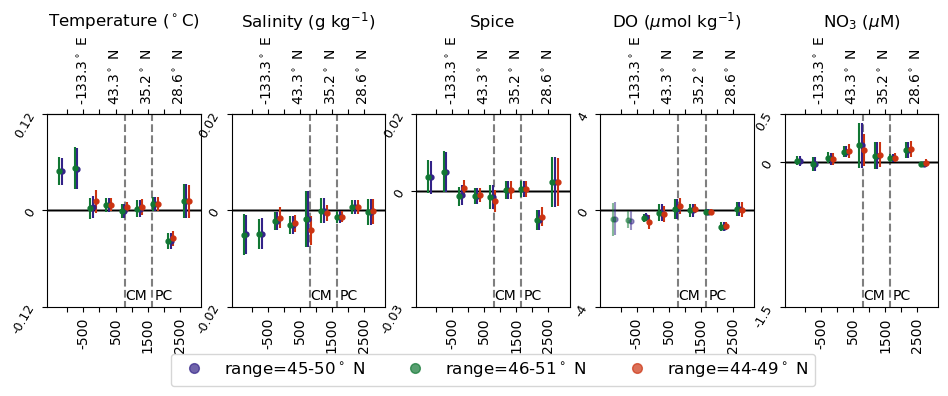

In [44]:
# now looking at how trends change with this new definition
varstrings = ['temperature (degC)','salinity (g kg-1)', 'spice',
       'DO (umol kg-1)', 'NO3 (uM)']

fig,ax = plt.subplots(1,len(varstrings),figsize=[2.3*len(varstrings),2.5])

for i in range(len(varstrings)):
    print(varstrings[i])

    ax[i].set_title(nicestring[i])
    slopes, yerr, span, count = plot_ratediff_NS_CI(cc1,varstrings[i], ax[i], '#332288')
    print('range 1 (violet)')
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] > 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('range 2 (green)')
    slopes, yerr, span, count = plot_ratediff_NS_CI(cc2,varstrings[i], ax[i], '#117733',offset=-80)
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] > 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")        
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('range 3 (red)')
    slopes, yerr, span, count = plot_ratediff_NS_CI(cc3,varstrings[i], ax[i], '#CC3311',offset=80)
    for j in range(len(slopes)):
        if (abs(slopes[j]) > yerr[j]) and span[j] > 30: 
            print(f"{j+1}) {np.round(slopes[j],4)} +/- {np.round(yerr[j],4)}, span={span[j]} years, length={count[j]}")
        else:
            print(f"{j+1}) span={span[j]} years, length={count[j]}")

    print('\n')

    # make secondary axis
    secax = ax[i].secondary_xaxis('top')
    secax.set_xlim(dmin, dmax)
    secax.set_xticks([-1000,-500,0,500,1000,1500,2000,2500])
    secax.set_xticklabels(['','-133.3$^\circ$ E','','43.3$^\circ$ N','','35.2$^\circ$ N','','28.6$^\circ$ N'],rotation=90)

    # add lines for JdF, Cape Mendocino, and Point Conception
    ax[i].plot([805,805],[-1000,1000],'k--',alpha=0.5) # Cape Mendocino
    ax[i].plot([1654,1654],[-1000,1000],'k--',alpha=0.5) # Point Conception
    ax[i].text(0.65,0.02,'CM',ha='right',va='bottom',transform=ax[i].transAxes,fontsize=10)
    ax[i].text(0.82,0.02,'PC',ha='right',va='bottom',transform=ax[i].transAxes,fontsize=10)

# # build legend handles    
legend_handles = []
inlegend = ["range=45-50$^\circ$ N",'range=46-51$^\circ$ N','range=44-49$^\circ$ N']
colours = ['#332288', '#117733', '#CC3311']
markers = ['o','o','o']
for i in range(len(inlegend)):
    legend_handles.append(mlines.Line2D([], [], 
                          marker=markers[i], linestyle='None',markersize=7,
                          markeredgecolor=colours[i], markerfacecolor=colours[i],alpha=0.7,
                          label=inlegend[i]))
# Add a figure-wide legend below the subplots
ax[2].legend(handles=legend_handles, loc='upper center', ncol=3, bbox_to_anchor=(0.5, -0.2), frameon=True,fontsize=12)

# plt.tight_layout()

plt.savefig('/ocean/rbeutel/MOAD/analysis-becca/Synthesis/output/Sensitivity_CC_BandLat.pdf',bbox_inches='tight')


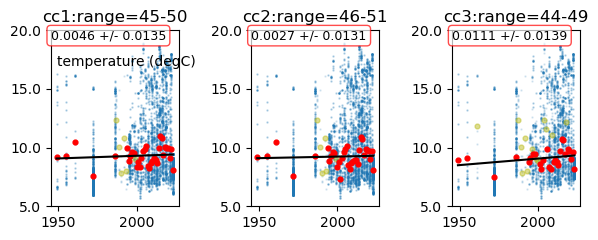

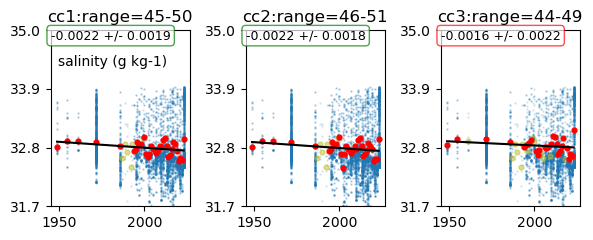

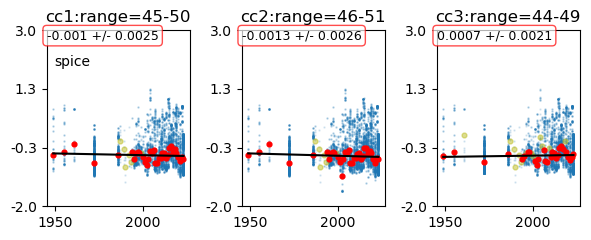

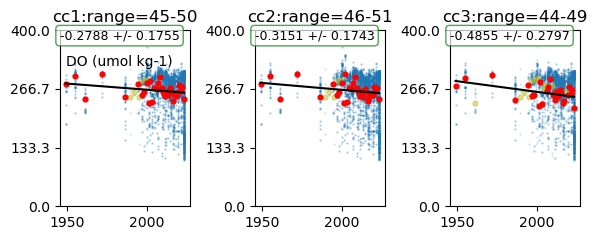

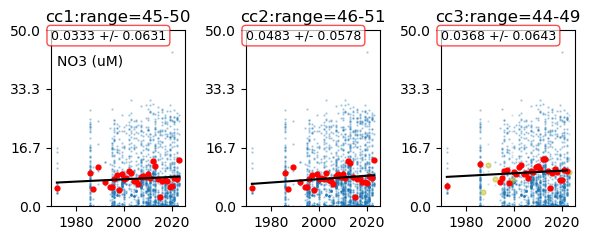

In [45]:
for var in varstrings:
    fig, ax = plt.subplots(1,3,figsize=[6,2.5])

    ax[0].text(0.05,0.8,var,transform=ax[0].transAxes,fontsize=10)

    trend_check(cc1,var,3,ax[0])
    ax[0].set_title("cc1:range=45-50")

    trend_check(cc2,var,3,ax[1])
    ax[1].set_title("cc2:range=46-51")

    trend_check(cc3,var,3,ax[2])
    ax[2].set_title("cc3:range=44-49")